### Dataset Loading and Structural Verification
Objective: Load the previously prepared Phase 3 dataset and examine its structure before analyzing chord-change patterns.
The dataset consists of overlapping 16-bar musical windows containing melody annotations, chord targets, musical timing information, and metadata.
This analysis will investigate harmonic rhythm, chord repetition, chord diversity, and progression regularity to identify possible limitations in the training data.
The existing dataset will remain unchanged. No additional filtering or preprocessing will be performed during this initial inspection.

In [1]:
# ==========================================
# PHASE 3 — HARMONIC RHYTHM ANALYSIS
# CELL 1 — DATASET LOADING
# ==========================================

import json
import pandas as pd

from pathlib import Path
from collections import Counter


# ==========================================
# 1. Project paths
# ==========================================

PROJECT_ROOT = (
    Path.home()
    / "Developer"
    / "vocal-harmonization"
)

DATASET_PATH = (
    PROJECT_ROOT
    / "datasets"
    / "mtg-jamendo"
    / "phase3-prepared"
    / "windows_v2_7family_timing_provisional.jsonl"
)

assert DATASET_PATH.exists(), (
    f"Dataset not found: {DATASET_PATH}"
)


# ==========================================
# 2. Load existing windows
# ==========================================

windows = []

with open(DATASET_PATH, "r") as file:

    for line in file:

        record = json.loads(line)
        windows.append(record)


print("PHASE 3 — HARMONIC RHYTHM DATASET")
print("--------------------------------")

print("Dataset:", DATASET_PATH.name)

print("Total windows:", len(windows))


# ==========================================
# 3. Dataset statistics
# ==========================================

track_ids = {
    w["track_id"]
    for w in windows
}

split_counts = Counter(
    w["split"]
    for w in windows
)

split_songs = {
    split: len({
        w["track_id"]
        for w in windows
        if w["split"] == split
    })
    for split in split_counts
}


print("\nDATASET SUMMARY")
print("--------------------------------")

print("Unique songs:", len(track_ids))

for split in ["train", "val", "test"]:

    print(
        f"{split}: "
        f"{split_counts[split]} windows, "
        f"{split_songs.get(split, 0)} songs"
    )


# ==========================================
# 4. Inspect window structure
# ==========================================

sample = windows[0]

print("\nWINDOW STRUCTURE")
print("--------------------------------")

for key, value in sample.items():

    if isinstance(value, list):

        print(
            f"{key}: LIST "
            f"({len(value)} elements)"
        )

    elif isinstance(value, dict):

        print(
            f"{key}: DICT "
            f"({list(value.keys())})"
        )

    else:

        print(
            f"{key}: {str(value)[:120]}"
        )


# ==========================================
# 5. Inspect nested structures
# ==========================================

print("\nNESTED DATA EXAMPLES")
print("--------------------------------")

for key, value in sample.items():

    if isinstance(value, list) and len(value) > 0:

        print(f"\n{key} — First element:")

        print(
            str(value[0])[:500]
        )

    elif isinstance(value, dict):

        print(f"\n{key} — Keys:")

        print(
            list(value.keys())
        )


# ==========================================
# 6. Basic verification
# ==========================================

assert len(windows) == 8909

assert len(track_ids) == 1069

print("\nVERIFICATION")
print("--------------------------------")

print("Expected windows: 8909")
print("Expected songs: 1069")

print("Dataset loaded correctly: YES")

print("Dataset modified: NO")
print("Filtering performed: NO")

print("\nReady for harmonic rhythm analysis!")

PHASE 3 — HARMONIC RHYTHM DATASET
--------------------------------
Dataset: windows_v2_7family_timing_provisional.jsonl
Total windows: 8909

DATASET SUMMARY
--------------------------------
Unique songs: 1069
train: 6282 windows, 752 songs
val: 1405 windows, 176 songs
test: 1222 windows, 141 songs

WINDOW STRUCTURE
--------------------------------
track_id: track_0000382
window_index: 0
split: train
artist_id: artist_000020
reference_key: C major
semitone_shift: 0
duration_sec: 33.43
window_start_sec: 0.01
genre_vector: LIST (5 elements)
has_selected_genre: False
melody: LIST (63 elements)
beat_targets: LIST (64 elements)
dataset_version: phase3_v2
quality_flags: DICT (['below_75_percent_valid_targets', 'missing_artist_id', 'mixed_meter', 'within_bar_meter_disagreement', 'beat_position_conflict'])
beat_grid: LIST (64 elements)
representation: DICT (['relative_roots', 'chord_families', 'no_chord_supervised'])

NESTED DATA EXAMPLES
--------------------------------

genre_vector — First e

### Chord Diversity and Harmonic-Change Frequency
Objective: Examine whether the previously prepared dataset contains harmonically static windows despite meeting the original chord-diversity requirements.
The analysis measures the number of unique root–family chord labels, observed chord-change frequency, chord-label dominance, and valid target coverage.
Diversity is examined separately at window and song levels to determine whether filtering requirements are consistently satisfied.
Chord transitions are counted only between consecutive beats containing reliable chord annotations. Unreliable or masked beats are not treated as chord changes.
The analysis uses training and validation data. No additional filtering is performed, and the test partition remains reserved for final evaluation.

In [2]:
# ==========================================
# HARMONIC RHYTHM ANALYSIS
# CELL 2 — CHORD DIVERSITY AND CHANGE FREQUENCY
# ==========================================

import pandas as pd
from collections import Counter, defaultdict


# ==========================================
# 1. Analyze individual windows
# ==========================================

def analyze_window_chords(window):

    beats = window["beat_targets"]

    labels = []

    for beat in beats:

        valid = (
            beat.get("model_target_mask") == 1
            and beat.get("root_id") is not None
            and beat.get("family_id") is not None
        )

        if valid:

            label = (
                int(beat["root_id"]),
                int(beat["family_id"])
            )

        else:
            label = None

        labels.append(label)

    # --------------------------------------
    # A. Unique chord labels
    # --------------------------------------

    valid_labels = [
        label
        for label in labels
        if label is not None
    ]

    chord_counts = Counter(valid_labels)

    unique_chords = len(chord_counts)

    # --------------------------------------
    # B. Valid target coverage
    # --------------------------------------

    total_beats = len(beats)
    valid_beats = len(valid_labels)

    coverage = (
        valid_beats / total_beats
        if total_beats
        else 0
    )

    # --------------------------------------
    # C. Consecutive chord changes
    # --------------------------------------

    valid_pairs = 0
    chord_changes = 0

    for i in range(1, len(labels)):

        previous = labels[i - 1]
        current = labels[i]

        # Do not bridge masked positions.

        if previous is None or current is None:
            continue

        valid_pairs += 1

        if previous != current:
            chord_changes += 1

    change_rate = (
        chord_changes / valid_pairs
        if valid_pairs
        else 0
    )

    # --------------------------------------
    # D. Chord dominance
    # --------------------------------------

    # Fraction of valid beats occupied
    # by the most frequent chord.
    #
    # This is NOT continuous duration.

    if chord_counts:

        most_common_chord, most_common_count = (
            chord_counts.most_common(1)[0]
        )

        dominant_share = (
            most_common_count / valid_beats
        )

    else:

        most_common_chord = None
        dominant_share = 0

    # --------------------------------------
    # E. Number of bars
    # --------------------------------------

    bar_indices = {
        beat["bar_index"]
        for beat in window["beat_grid"]
    }

    total_bars = len(bar_indices)

    return {
        "track_id": window["track_id"],
        "window_index": window["window_index"],
        "split": window["split"],

        "total_bars": total_bars,
        "total_beats": total_beats,

        "valid_beats": valid_beats,
        "target_coverage": coverage,

        "unique_chords": unique_chords,

        "valid_pairs": valid_pairs,
        "chord_changes": chord_changes,

        "change_rate": change_rate,

        "changes_per_bar": (
            chord_changes / total_bars
            if total_bars else 0
        ),

        "dominant_chord_share":
            dominant_share,

        "most_common_chord":
            most_common_chord,

        "observable_pair_fraction": (
            valid_pairs / max(total_beats - 1, 1)
        )
    }


# ==========================================
# 2. Analyze training and validation windows
# ==========================================

# Keep the test partition untouched.

analysis_windows = [
    w for w in windows
    if w["split"] in ["train", "val"]
]

results = [
    analyze_window_chords(w)
    for w in analysis_windows
]

chord_analysis_df = pd.DataFrame(results)


print("CHORD DIVERSITY ANALYSIS")
print("--------------------------------")

print(
    "Windows analyzed:",
    len(chord_analysis_df)
)

print(
    "Training windows:",
    (chord_analysis_df["split"] == "train").sum()
)

print(
    "Validation windows:",
    (chord_analysis_df["split"] == "val").sum()
)


# ==========================================
# 3. Window-level chord diversity
# ==========================================

def diversity_category(count):

    if count >= 4:
        return "4+"

    return str(count)


chord_analysis_df["diversity_group"] = (
    chord_analysis_df["unique_chords"]
    .apply(diversity_category)
)

diversity_table = pd.crosstab(
    chord_analysis_df["diversity_group"],
    chord_analysis_df["split"]
)

diversity_table = diversity_table.reindex(
    ["0", "1", "2", "3", "4+"],
    fill_value=0
)

print("\nUNIQUE CHORDS PER WINDOW")
print("--------------------------------")

display(diversity_table)


# ==========================================
# 4. Verify song-level chord diversity
# ==========================================

song_chords = defaultdict(set)

for window in analysis_windows:

    key = (
        window["split"],
        window["track_id"]
    )

    for beat in window["beat_targets"]:

        if (
            beat.get("model_target_mask") == 1
            and beat.get("root_id") is not None
            and beat.get("family_id") is not None
        ):

            label = (
                int(beat["root_id"]),
                int(beat["family_id"])
            )

            song_chords[key].add(label)


song_rows = []

for (split, track_id), chord_set in song_chords.items():

    song_rows.append({
        "split": split,
        "track_id": track_id,
        "unique_chords": len(chord_set)
    })


song_diversity_df = pd.DataFrame(song_rows)

song_diversity_df["diversity_group"] = (
    song_diversity_df["unique_chords"]
    .apply(diversity_category)
)

song_diversity_table = pd.crosstab(
    song_diversity_df["diversity_group"],
    song_diversity_df["split"]
)

song_diversity_table = song_diversity_table.reindex(
    ["0", "1", "2", "3", "4+"],
    fill_value=0
)

print("\nUNIQUE CHORDS PER SONG")
print("--------------------------------")

display(song_diversity_table)


# ==========================================
# 5. Chord-change frequency distribution
# ==========================================

change_summary = (
    chord_analysis_df
    .groupby("split")
    .agg(
        windows=("track_id", "size"),

        mean_changes=("chord_changes", "mean"),

        median_changes=("chord_changes", "median"),

        min_changes=("chord_changes", "min"),

        max_changes=("chord_changes", "max"),

        mean_change_rate=("change_rate", "mean"),

        median_change_rate=("change_rate", "median"),

        mean_dominant_share=(
            "dominant_chord_share",
            "mean"
        ),

        mean_target_coverage=(
            "target_coverage",
            "mean"
        ),

        mean_observable_pair_fraction=(
            "observable_pair_fraction",
            "mean"
        )
    )
    .reset_index()
)

print("\nCHORD-CHANGE FREQUENCY SUMMARY")
print("--------------------------------")

display(change_summary.round(4))


# ==========================================
# 6. Group windows by observed changes
# ==========================================

def change_category(count):

    if count == 0:
        return "0 changes"

    elif count <= 2:
        return "1–2 changes"

    elif count <= 4:
        return "3–4 changes"

    elif count <= 8:
        return "5–8 changes"

    elif count <= 16:
        return "9–16 changes"

    return "17+ changes"


chord_analysis_df["change_group"] = (
    chord_analysis_df["chord_changes"]
    .apply(change_category)
)

change_distribution = pd.crosstab(
    chord_analysis_df["change_group"],
    chord_analysis_df["split"]
)

change_distribution = change_distribution.reindex(
    [
        "0 changes",
        "1–2 changes",
        "3–4 changes",
        "5–8 changes",
        "9–16 changes",
        "17+ changes"
    ],
    fill_value=0
)

print("\nCHORD CHANGES PER 16-BAR WINDOW")
print("--------------------------------")

display(change_distribution)


# ==========================================
# 7. Four-chord windows with few changes
# ==========================================

# These are candidates for investigation,
# NOT automatic exclusions.

suspicious_windows = (
    chord_analysis_df[
        (chord_analysis_df["split"] == "train")
        &
        (chord_analysis_df["unique_chords"] >= 4)
        &
        (chord_analysis_df["chord_changes"] <= 4)
    ]
    .sort_values(
        [
            "chord_changes",
            "dominant_chord_share"
        ],
        ascending=[True, False]
    )
)

print("\nFOUR-CHORD WINDOWS WITH FEW OBSERVED CHANGES")
print("--------------------------------")

print(
    "Candidate windows:",
    len(suspicious_windows)
)

display(
    suspicious_windows[
        [
            "track_id",
            "window_index",
            "unique_chords",
            "chord_changes",
            "change_rate",
            "dominant_chord_share",
            "target_coverage",
            "observable_pair_fraction"
        ]
    ].head(20).round(4)
)


# ==========================================
# 8. Quantify potential imbalance
# ==========================================

train_df = chord_analysis_df[
    chord_analysis_df["split"] == "train"
]

train_4plus = train_df[
    train_df["unique_chords"] >= 4
]

print("\nTRAINING DATA SUMMARY")
print("--------------------------------")

print(
    "Training windows:",
    len(train_df)
)

print(
    "Windows with 4+ unique chords:",
    len(train_4plus)
)

print(
    "Windows with fewer than 4 chords:",
    int((train_df["unique_chords"] < 4).sum())
)

print(
    "Windows with <= 4 observed changes:",
    int((train_df["chord_changes"] <= 4).sum())
)

print(
    "Windows with 4+ chords AND <= 4 changes:",
    len(suspicious_windows)
)

print(
    "Windows where one chord occupies >= 75%:",
    int(
        (
            train_df["dominant_chord_share"] >= 0.75
        ).sum()
    )
)


# ==========================================
# 9. Final verification
# ==========================================

assert len(chord_analysis_df) == 7687

assert (
    (chord_analysis_df["total_bars"] == 16)
    .all()
)

assert (
    chord_analysis_df["chord_changes"]
    <= chord_analysis_df["valid_pairs"]
).all()

print("\nFINAL VERIFICATION")
print("--------------------------------")

print("Expected analysis windows: 7687")
print("All windows contain 16 bars: YES")

print("Original dataset modified: NO")
print("Filtering performed: NO")
print("Test partition analyzed: NO")

print("\nChord diversity analysis completed!")

CHORD DIVERSITY ANALYSIS
--------------------------------
Windows analyzed: 7687
Training windows: 6282
Validation windows: 1405

UNIQUE CHORDS PER WINDOW
--------------------------------


split,train,val
diversity_group,,
0,0,0
1,0,0
2,368,100
3,1042,246
4+,4872,1059



UNIQUE CHORDS PER SONG
--------------------------------


split,train,val
diversity_group,,
0,0,0
1,0,0
2,4,1
3,10,0
4+,738,175



CHORD-CHANGE FREQUENCY SUMMARY
--------------------------------


...


CHORD CHANGES PER 16-BAR WINDOW
--------------------------------


split,train,val
change_group,,
0 changes,186,45
1–2 changes,1206,281
3–4 changes,1722,413
5–8 changes,2191,459
9–16 changes,893,186
17+ changes,84,21



FOUR-CHORD WINDOWS WITH FEW OBSERVED CHANGES
--------------------------------
Candidate windows: 2066


,track_id,window_index,unique_chords,chord_changes,change_rate,dominant_chord_share,target_coverage,observable_pair_fraction
2060,track_0880702,30,4,0,0.0,0.9016,0.9531,0.9048
4549,track_1084672,5,4,0,0.0,0.9000,0.9375,0.8730
2752,track_1028800,3,5,0,0.0,0.8644,0.9219,0.8413
6635,track_1159743,15,4,0,0.0,0.8519,0.8438,0.7097
6415,track_1156091,4,4,0,0.0,0.8197,0.9531,0.9048
2839,track_1032330,3,4,0,0.0,0.7966,0.9219,0.8413
5174,track_1115077,3,4,0,0.0,0.7931,0.9062,0.8065
1078,track_0479836,1,4,0,0.0,0.7833,0.9375,0.8889
4150,track_1072572,40,4,0,0.0,0.7667,0.9375,0.8889
185,track_0031433,4,4,0,0.0,0.7500,0.9375,0.8889



TRAINING DATA SUMMARY
--------------------------------
Training windows: 6282
Windows with 4+ unique chords: 4872
Windows with fewer than 4 chords: 1410
Windows with <= 4 observed changes: 3114
Windows with 4+ chords AND <= 4 changes: 2066
Windows where one chord occupies >= 75%: 507

FINAL VERIFICATION
--------------------------------
Expected analysis windows: 7687
All windows contain 16 bars: YES
Original dataset modified: NO
Filtering performed: NO
Test partition analyzed: NO

Chord diversity analysis completed!


### Masking-Aware Chord Transition Analysis
Objective: Investigate whether unreliable beat annotations cause the dataset's measured chord-change frequency to underestimate actual harmonic activity.
The analysis distinguishes directly observed chord transitions from changes inferred between reliable chord labels separated by masked beats.
A masking-aware minimum change count is calculated without assigning artificial chord labels to uncertain positions.
Windows previously classified as having zero chord changes are re-examined, and representative chord sequences are displayed.
The original dataset remains unchanged, and the test partition is excluded.

In [3]:
# ==========================================
# HARMONIC RHYTHM ANALYSIS
# CELL 3 — MASKING-AWARE CHORD TRANSITIONS
# ==========================================

import pandas as pd
from collections import Counter


# ==========================================
# 1. Extract reliable chord sequence
# ==========================================

def extract_chord_sequence(window):

    sequence = []

    for beat in window["beat_targets"]:

        valid = (
            beat.get("model_target_mask") == 1
            and beat.get("root_id") is not None
            and beat.get("family_id") is not None
        )

        if valid:
            chord = (
                int(beat["root_id"]),
                int(beat["family_id"])
            )
        else:
            chord = None

        sequence.append(chord)

    return sequence


# ==========================================
# 2. Analyze transitions across masked gaps
# ==========================================

def audit_chord_transitions(window):

    sequence = extract_chord_sequence(window)

    reliable_indices = [
        i for i, chord in enumerate(sequence)
        if chord is not None
    ]

    direct_changes = 0
    gap_changes = 0

    masked_gaps = 0
    same_chord_gaps = 0

    gap_details = []

    # Compare successive reliable observations.

    for previous_i, current_i in zip(
        reliable_indices[:-1],
        reliable_indices[1:]
    ):

        previous = sequence[previous_i]
        current = sequence[current_i]

        distance = current_i - previous_i

        chord_changed = previous != current

        # ----------------------------------
        # A. Adjacent reliable beats
        # ----------------------------------

        if distance == 1:

            if chord_changed:
                direct_changes += 1

        # ----------------------------------
        # B. Reliable beats separated by masks
        # ----------------------------------

        else:

            masked_gaps += 1

            if chord_changed:
                gap_changes += 1

            else:
                same_chord_gaps += 1

            gap_details.append({
                "before_beat": previous_i + 1,
                "after_beat": current_i + 1,

                "masked_beats": distance - 1,

                "before_chord": previous,
                "after_chord": current,

                "different_chords": chord_changed,

                "masked_states": [
                    window["beat_targets"][j].get(
                        "target_state"
                    )
                    for j in range(
                        previous_i + 1,
                        current_i
                    )
                ]
            })

    # --------------------------------------
    # C. Minimum number of changes
    # --------------------------------------

    minimum_changes = (
        direct_changes + gap_changes
    )

    unique_chords = len({
        chord for chord in sequence
        if chord is not None
    })

    # Every new distinct chord requires
    # at least one transition somewhere.

    assert minimum_changes >= max(
        0, unique_chords - 1
    )

    return {
        "track_id": window["track_id"],
        "window_index": window["window_index"],
        "split": window["split"],

        "unique_chords": unique_chords,

        "direct_changes": direct_changes,
        "gap_crossing_changes": gap_changes,

        "minimum_changes": minimum_changes,

        "masked_gaps": masked_gaps,
        "same_chord_gaps": same_chord_gaps,

        "masked_beats": sum(
            chord is None for chord in sequence
        ),

        "gap_details": gap_details
    }


# ==========================================
# 3. Analyze training and validation
# ==========================================

transition_results = [
    audit_chord_transitions(w)
    for w in analysis_windows
]

transition_df = pd.DataFrame(
    transition_results
)


print("MASKING-AWARE TRANSITION ANALYSIS")
print("--------------------------------")

print(
    "Windows analyzed:",
    len(transition_df)
)


# ==========================================
# 4. Compare old and corrected counts
# ==========================================

comparison_rows = []

for split in ["train", "val"]:

    subset = transition_df[
        transition_df["split"] == split
    ]

    comparison_rows.append({

        "Split": split,

        "Windows": len(subset),

        "Direct changes":
            int(subset["direct_changes"].sum()),

        "Gap-crossing changes":
            int(subset["gap_crossing_changes"].sum()),

        "Minimum confirmed changes":
            int(subset["minimum_changes"].sum()),

        "Mean direct changes":
            subset["direct_changes"].mean(),

        "Mean minimum changes":
            subset["minimum_changes"].mean(),

        "Median direct changes":
            subset["direct_changes"].median(),

        "Median minimum changes":
            subset["minimum_changes"].median()
    })


transition_comparison = pd.DataFrame(
    comparison_rows
)

print("\nDIRECT VS MASKING-AWARE CHANGES")
print("--------------------------------")

display(
    transition_comparison.round(3)
)


# ==========================================
# 5. Re-examine zero-change windows
# ==========================================

zero_rows = []

for split in ["train", "val"]:

    subset = transition_df[
        transition_df["split"] == split
    ]

    zero_rows.append({

        "Split": split,

        "Zero direct changes":
            int(
                (subset["direct_changes"] == 0).sum()
            ),

        "Zero minimum changes":
            int(
                (subset["minimum_changes"] == 0).sum()
            ),

        "4+ chords, zero direct changes":
            int(
                (
                    (subset["unique_chords"] >= 4)
                    &
                    (subset["direct_changes"] == 0)
                ).sum()
            ),

        "4+ chords, zero minimum changes":
            int(
                (
                    (subset["unique_chords"] >= 4)
                    &
                    (subset["minimum_changes"] == 0)
                ).sum()
            )
    })


zero_comparison = pd.DataFrame(
    zero_rows
)

print("\nZERO-CHANGE WINDOW INVESTIGATION")
print("--------------------------------")

display(zero_comparison)


# ==========================================
# 6. Quantify masked transition evidence
# ==========================================

train_transitions = transition_df[
    transition_df["split"] == "train"
]

total_direct = int(
    train_transitions["direct_changes"].sum()
)

total_gap = int(
    train_transitions["gap_crossing_changes"].sum()
)

total_minimum = total_direct + total_gap

print("\nTRAINING TRANSITION EVIDENCE")
print("--------------------------------")

print("Direct changes:", total_direct)

print("Changes across masked gaps:", total_gap)

print("Minimum confirmed changes:", total_minimum)

print(
    "Share of minimum changes crossing masks:",
    f"{total_gap / total_minimum:.2%}"
    if total_minimum else "N/A"
)


# ==========================================
# 7. Find suspicious windows
# ==========================================

# Select windows with:
#
# - At least four unique chords.
# - Zero directly observed changes.
# - At least three gap-crossing changes.

suspicious = transition_df[
    (transition_df["split"] == "train")
    &
    (transition_df["unique_chords"] >= 4)
    &
    (transition_df["direct_changes"] == 0)
    &
    (transition_df["gap_crossing_changes"] >= 3)
].copy()

suspicious = suspicious.sort_values(
    [
        "gap_crossing_changes",
        "masked_beats"
    ],
    ascending=[False, True]
)


print("\nWINDOWS WITH HIDDEN CHORD CHANGES")
print("--------------------------------")

print("Candidate windows:", len(suspicious))

display(
    suspicious[
        [
            "track_id",
            "window_index",
            "unique_chords",
            "direct_changes",
            "gap_crossing_changes",
            "minimum_changes",
            "masked_beats"
        ]
    ].head(15)
)


# ==========================================
# 8. Display complete chord sequences
# ==========================================

# Use actual plan labels from the dataset.

def display_window_sequence(window):

    print(
        f"\nTRACK: {window['track_id']}"
        f" | WINDOW: {window['window_index']}"
    )

    print("--------------------------------")

    sequence = extract_chord_sequence(window)

    # Group by actual bar index, not
    # assumed four-beat groupings.

    current_bar = None
    bar_entries = []

    for i, (beat, grid) in enumerate(
        zip(
            window["beat_targets"],
            window["beat_grid"]
        )
    ):

        bar = int(grid["bar_index"]) + 1

        if current_bar is not None and bar != current_bar:

            print(
                f"Bar {current_bar:02d}: "
                + " | ".join(bar_entries)
            )

            bar_entries = []

        current_bar = bar

        if sequence[i] is None:

            label = "[MASK]"

        else:

            label = beat["plan_label"]

        position = grid["beat_in_bar"]

        bar_entries.append(
            f"{position}:{label}"
        )

    if bar_entries:

        print(
            f"Bar {current_bar:02d}: "
            + " | ".join(bar_entries)
        )


# ==========================================
# 9. Inspect three actual examples
# ==========================================

print("\nREAL CHORD SEQUENCE EXAMPLES")
print("--------------------------------")

example_rows = suspicious.head(3)

for _, row in example_rows.iterrows():

    matching_window = next(
        w for w in analysis_windows
        if (
            w["track_id"] == row["track_id"]
            and
            w["window_index"] == row["window_index"]
        )
    )

    display_window_sequence(matching_window)

    audit = audit_chord_transitions(
        matching_window
    )

    print("\nChanges across masked gaps:")

    for gap in audit["gap_details"]:

        if gap["different_chords"]:

            print(
                f"  Beat {gap['before_beat']} "
                f"→ Beat {gap['after_beat']} "
                f"({gap['masked_beats']} masked): "
                f"{gap['before_chord']} "
                f"→ {gap['after_chord']}"
            )


# ==========================================
# 10. Final verification
# ==========================================

assert len(transition_df) == 7687

assert (
    transition_df["minimum_changes"]
    >= transition_df["direct_changes"]
).all()

assert (
    transition_df["minimum_changes"]
    >= transition_df["unique_chords"] - 1
).all()

print("\nFINAL VERIFICATION")
print("--------------------------------")

print("All minimum change bounds valid: YES")

print("Original dataset modified: NO")
print("Filtering performed: NO")
print("Test partition accessed: NO")

print("\nMasking-aware transition analysis complete!")

MASKING-AWARE TRANSITION ANALYSIS
--------------------------------
Windows analyzed: 7687

DIRECT VS MASKING-AWARE CHANGES
--------------------------------


,Split,Windows,Direct changes,Gap-crossing changes,Minimum confirmed changes,Mean direct changes,Mean minimum changes,Median direct changes,Median minimum changes
0,train,6282,33127,35290,68417,5.273,10.891,5.0,10.0
1,val,1405,7267,7688,14955,5.172,10.644,4.0,10.0



ZERO-CHANGE WINDOW INVESTIGATION
--------------------------------


,Split,Zero direct changes,Zero minimum changes,"4+ chords, zero direct changes","4+ chords, zero minimum changes"
0,train,186,0,73,0
1,val,45,0,19,0



TRAINING TRANSITION EVIDENCE
--------------------------------
Direct changes: 33127
Changes across masked gaps: 35290
Minimum confirmed changes: 68417
Share of minimum changes crossing masks: 51.58%

WINDOWS WITH HIDDEN CHORD CHANGES
--------------------------------
Candidate windows: 73


,track_id,window_index,unique_chords,direct_changes,gap_crossing_changes,minimum_changes,masked_beats
6220,track_1138689,12,4,0,16,16,16
339,track_0047049,7,4,0,15,15,15
4464,track_1078511,5,5,0,15,15,16
5340,track_1121406,8,4,0,14,14,14
5341,track_1121406,9,4,0,14,14,14
4367,track_1078426,8,5,0,14,14,15
2389,track_0962723,16,6,0,12,12,12
193,track_0031434,7,6,0,11,11,11
1079,track_0479836,2,7,0,11,11,11
2849,track_1032331,4,4,0,11,11,11



REAL CHORD SEQUENCE EXAMPLES
--------------------------------

TRACK: track_1138689 | WINDOW: 12
--------------------------------
Bar 01: 1:V:MAJ | 2:[MASK] | 3:I:MAJ | 4:I:MAJ
Bar 02: 1:I:MAJ | 2:[MASK] | 3:IV:MAJ | 4:IV:MAJ
Bar 03: 1:IV:MAJ | 2:[MASK] | 3:I:MAJ | 4:I:MAJ
Bar 04: 1:I:MAJ | 2:[MASK] | 3:V:MAJ | 4:V:MAJ
Bar 05: 1:V:MAJ | 2:[MASK] | 3:I:MAJ | 4:I:MAJ
Bar 06: 1:I:MAJ | 2:[MASK] | 3:IV:MAJ | 4:IV:MAJ
Bar 07: 1:IV:MAJ | 2:[MASK] | 3:I:MAJ | 4:I:MAJ
Bar 08: 1:I:MAJ | 2:[MASK] | 3:V:MAJ | 4:V:MAJ
Bar 09: 1:V:MAJ | 2:[MASK] | 3:I:MAJ | 4:I:MAJ
Bar 10: 1:I:MAJ | 2:[MASK] | 3:IV:MAJ | 4:IV:MAJ
Bar 11: 1:IV:MAJ | 2:[MASK] | 3:I:MAJ | 4:I:MAJ
Bar 12: 1:I:MAJ | 2:[MASK] | 3:V:MAJ | 4:V:MAJ
Bar 13: 1:V:MAJ | 2:[MASK] | 3:VI:MIN | 4:VI:MIN
Bar 14: 1:VI:MIN | 2:[MASK] | 3:IV:MAJ | 4:IV:MAJ
Bar 15: 1:IV:MAJ | 2:[MASK] | 3:I:MAJ | 4:I:MAJ
Bar 16: 1:I:MAJ | 2:[MASK] | 3:V:MAJ | 4:V:MAJ

Changes across masked gaps:
  Beat 1 → Beat 3 (1 masked): (7, 0) → (0, 0)
  Beat 5 → Beat 7 (1 masked

### Original Chord-Event Source Verification
Objective: Locate the original timed chord annotations corresponding to selected Phase 3 windows.
The analysis examines available chord-event files, their annotation formats, event counts, and timing alignment with the prepared 16-bar windows.
This investigation will establish a reliable source for measuring chord durations, harmonic-change intervals, and harmonic-rhythm regularity without relying on masked beat-level labels.
No filtering or modifications will be performed.

In [4]:
# ==========================================
# HARMONIC RHYTHM ANALYSIS
# CELL 4 — ORIGINAL CHORD EVENT INSPECTION
# ==========================================

import json
import pandas as pd
from pathlib import Path


# ==========================================
# 1. Original extraction pipeline
# ==========================================

PIPELINE_OUTPUTS = (
    PROJECT_ROOT
    / "datasets"
    / "mtg-jamendo"
    / "melody-chord-extraction-pipeline"
    / "outputs"
)

print("ORIGINAL CHORD SOURCE")
print("--------------------------------")

print("Pipeline:", PIPELINE_OUTPUTS)

print(
    "Pipeline exists:",
    PIPELINE_OUTPUTS.exists()
)


# ==========================================
# 2. Select three investigated examples
# ==========================================

EXAMPLE_TRACKS = [
    ("track_1138689", 12),
    ("track_0047049", 7),
    ("track_1078511", 5)
]

SOURCE_FILES = [
    "chords/submission.json",
    "chords/full.json",
    "roman/submission.json",
    "roman/full.json"
]


# ==========================================
# 3. Find matching dataset window
# ==========================================

window_lookup = {
    (w["track_id"], w["window_index"]): w
    for w in analysis_windows
}


# ==========================================
# 4. Inspect source files
# ==========================================

source_rows = []

available_sources = []

for track_id, window_index in EXAMPLE_TRACKS:

    window = window_lookup[
        (track_id, window_index)
    ]

    window_start = float(
        window["window_start_sec"]
    )

    window_end = (
        window_start
        + float(window["duration_sec"])
    )

    print("\n" + "=" * 60)

    print("TRACK:", track_id)
    print("WINDOW:", window_index)

    print(
        "Window absolute time:",
        f"{window_start:.2f}s – {window_end:.2f}s"
    )

    print("=" * 60)

    for source_name in SOURCE_FILES:

        path = (
            PIPELINE_OUTPUTS
            / track_id
            / source_name
        )

        if not path.exists():

            source_rows.append({
                "Track": track_id,
                "Source": source_name,
                "Available": False,
                "Total events": 0,
                "Window events": 0
            })

            print(
                f"\nMISSING: {source_name}"
            )

            continue

        with open(path, "r") as file:

            data = json.load(file)

        events = data.get(
            "events", []
        )

        # Events overlapping our window.

        overlapping = [
            event
            for event in events
            if (
                float(event["end_sec"]) > window_start
                and
                float(event["start_sec"]) < window_end
            )
        ]

        source_rows.append({
            "Track": track_id,
            "Source": source_name,
            "Available": True,
            "Total events": len(events),
            "Window events": len(overlapping)
        })

        available_sources.append(
            (track_id, source_name, path)
        )

        print(
            f"\nSOURCE: {source_name}"
        )

        print(
            "Total song events:",
            len(events)
        )

        print(
            "Events overlapping window:",
            len(overlapping)
        )

        if events:

            print(
                "Event fields:",
                list(events[0].keys())
            )

        # ----------------------------------
        # Show first eight overlapping events
        # ----------------------------------

        rows = []

        for event in overlapping[:8]:

            start_sec = float(
                event["start_sec"]
            )

            end_sec = float(
                event["end_sec"]
            )

            label = (
                event.get("chord_label")
                or event.get("original_chord_label")
                or event.get("basic_label")
                or "UNKNOWN"
            )

            rows.append({
                "Start (s)": round(
                    start_sec, 3
                ),

                "End (s)": round(
                    end_sec, 3
                ),

                "Duration (s)": round(
                    end_sec - start_sec, 3
                ),

                "Chord": label
            })

        if rows:

            display(
                pd.DataFrame(rows)
            )


# ==========================================
# 5. Source availability summary
# ==========================================

source_availability_df = pd.DataFrame(
    source_rows
)

print("\nSOURCE AVAILABILITY SUMMARY")
print("--------------------------------")

display(
    source_availability_df
)


# ==========================================
# 6. Final verification
# ==========================================

print("\nFINAL VERIFICATION")
print("--------------------------------")

print(
    "Available source files:",
    len(available_sources)
)

print(
    "Example tracks investigated:",
    len(EXAMPLE_TRACKS)
)

print("Original dataset modified: NO")
print("Filtering performed: NO")
print("Test partition accessed: NO")

if available_sources:

    print(
        "\nOriginal chord-event files located."
    )

else:

    print(
        "\nOriginal chord files not found at "
        "the expected pipeline location."
    )

ORIGINAL CHORD SOURCE
--------------------------------
Pipeline: /Users/praise/Developer/vocal-harmonization/datasets/mtg-jamendo/melody-chord-extraction-pipeline/outputs
Pipeline exists: True

TRACK: track_1138689
WINDOW: 12
Window absolute time: 201.31s – 232.01s

SOURCE: chords/submission.json
Total song events: 122
Events overlapping window: 17
Event fields: ['start_sec', 'end_sec', 'chord_label', 'root', 'quality', 'bass_degree']


,Start (s),End (s),Duration (s),Chord
0,200.20,202.08,1.88,D:maj
1,202.08,203.99,1.91,G:maj
2,203.99,205.89,1.90,C:maj
3,205.89,207.82,1.93,G:maj
4,207.82,209.70,1.88,D:maj
5,209.70,211.65,1.95,G:maj
6,211.65,213.51,1.86,C:maj
7,213.51,215.43,1.92,G:maj



SOURCE: chords/full.json
Total song events: 122
Events overlapping window: 17
Event fields: ['start_sec', 'end_sec', 'chord_label', 'root', 'quality', 'bass_degree']


,Start (s),End (s),Duration (s),Chord
0,200.20,202.08,1.88,D:maj
1,202.08,203.99,1.91,G:maj
2,203.99,205.89,1.90,C:maj
3,205.89,207.82,1.93,G:maj
4,207.82,209.70,1.88,D:maj
5,209.70,211.65,1.95,G:maj
6,211.65,213.51,1.86,C:maj
7,213.51,215.43,1.92,G:maj



SOURCE: roman/submission.json
Total song events: 122
Events overlapping window: 17
Event fields: ['track_id', 'start_sec', 'end_sec', 'original_chord_label', 'relative_root_semitones', 'relative_root', 'family', 'basic_label', 'mapping_status', 'bass_degree']


...


SOURCE: roman/full.json
Total song events: 157
Events overlapping window: 17
Event fields: ['track_id', 'start_sec', 'end_sec', 'original_chord_label', 'relative_root_semitones', 'relative_root', 'family', 'basic_label', 'mapping_status', 'bass_degree']


,Start (s),End (s),Duration (s),Chord
0,63.23,64.25,1.02,A:maj
1,64.25,65.46,1.21,B:maj
2,65.46,66.55,1.09,E:maj
3,66.55,67.78,1.23,C#:min
4,67.78,68.89,1.11,A:maj
5,68.89,69.98,1.09,E:maj
6,69.98,71.15,1.17,B:maj
7,71.15,72.33,1.18,C#:min



SOURCE AVAILABILITY SUMMARY
--------------------------------


,Track,Source,Available,Total events,Window events
0,track_1138689,chords/submission.json,True,122,17
1,track_1138689,chords/full.json,True,122,17
2,track_1138689,roman/submission.json,True,122,17
3,track_1138689,roman/full.json,True,122,17
4,track_0047049,chords/submission.json,True,141,16
5,track_0047049,chords/full.json,True,141,16
6,track_0047049,roman/submission.json,True,141,16
7,track_0047049,roman/full.json,True,141,16
8,track_1078511,chords/submission.json,True,157,17
9,track_1078511,chords/full.json,True,157,17



FINAL VERIFICATION
--------------------------------
Available source files: 12
Example tracks investigated: 3
Original dataset modified: NO
Filtering performed: NO
Test partition accessed: NO

Original chord-event files located.


#### Original Chord Annotation Alignment Audit
Objective: Verify whether the original timed chord events match the relative chord roots stored in the prepared Phase 3 windows.
Each reliable beat is aligned with the original chord event occupying the largest proportion of that beat.
The analysis compares absolute chord roots, key-relative roots, and transposed roots to identify the normalization used by the prepared dataset.
Only training and validation windows are examined. No chord labels are modified, and no filtering is performed.
The results will determine whether the original chord-event files are suitable for subsequent harmonic-duration and regularity analysis.

In [5]:
# ==========================================
# HARMONIC RHYTHM ANALYSIS
# CELL 5 — ORIGINAL CHORD ALIGNMENT AUDIT
# ==========================================

import json
import pandas as pd

from pathlib import Path
from functools import lru_cache
from bisect import bisect_right
from collections import defaultdict


# ==========================================
# 1. Note-name conversion
# ==========================================

NOTE_PC = {
    "C": 0, "B#": 0,
    "C#": 1, "Db": 1,
    "D": 2,
    "D#": 3, "Eb": 3,
    "E": 4, "Fb": 4,
    "F": 5, "E#": 5,
    "F#": 6, "Gb": 6,
    "G": 7,
    "G#": 8, "Ab": 8,
    "A": 9,
    "A#": 10, "Bb": 10,
    "B": 11, "Cb": 11
}


def note_to_pc(note):

    if note is None:
        return None

    note = str(note).strip()

    note = (
        note.replace("♯", "#")
            .replace("♭", "b")
    )

    if not note:
        return None

    note = note[0].upper() + note[1:]

    return NOTE_PC.get(note)


def reference_key_pc(window):

    # Example: "G major" -> G -> 7

    key = window.get("reference_key", "")

    tonic = str(key).split()[0]

    return note_to_pc(tonic)


# ==========================================
# 2. Load original chord events
# ==========================================

# Cache song files because each song
# contributes multiple overlapping windows.

@lru_cache(maxsize=None)
def load_original_chords(track_id):

    path = (
        PIPELINE_OUTPUTS
        / track_id
        / "chords"
        / "submission.json"
    )

    if not path.exists():
        return None

    with open(path, "r") as f:
        data = json.load(f)

    events = []

    for event in data.get("events", []):

        start = float(event["start_sec"])
        end = float(event["end_sec"])

        if end <= start:
            continue

        events.append({
            "start": start,
            "end": end,
            "root": event.get("root"),
            "quality": event.get("quality"),
            "label": event.get("chord_label")
        })

    events.sort(key=lambda x: x["start"])

    return events


# ==========================================
# 3. Find dominant chord within a beat
# ==========================================

def dominant_original_chord(
    events,
    event_starts,
    beat_start,
    beat_end
):

    duration = beat_end - beat_start

    if duration <= 0:
        return None, 0.0

    # Search near the beat's starting time.

    index = max(
        0,
        bisect_right(
            event_starts,
            beat_start
        ) - 1
    )

    best_event = None
    best_overlap = 0.0

    while index < len(events):

        event = events[index]

        if event["start"] >= beat_end:
            break

        overlap = max(
            0.0,
            min(
                beat_end,
                event["end"]
            )
            -
            max(
                beat_start,
                event["start"]
            )
        )

        if overlap > best_overlap:

            best_overlap = overlap
            best_event = event

        index += 1

    occupancy = best_overlap / duration

    return best_event, occupancy


# ==========================================
# 4. Compare original and prepared labels
# ==========================================

audit_rows = []

missing_source_windows = 0
missing_reference_key_windows = 0

reliable_beat_count = 0
comparable_beat_count = 0

for window in analysis_windows:

    track_id = window["track_id"]

    events = load_original_chords(track_id)

    if events is None:

        missing_source_windows += 1
        continue

    key_pc = reference_key_pc(window)

    if key_pc is None:

        missing_reference_key_windows += 1
        continue

    shift = int(
        window.get("semitone_shift", 0)
    )

    event_starts = [
        event["start"]
        for event in events
    ]

    window_start = float(
        window["window_start_sec"]
    )

    for beat, grid in zip(
        window["beat_targets"],
        window["beat_grid"]
    ):

        valid = (
            beat.get("model_target_mask") == 1
            and beat.get("root_id") is not None
        )

        if not valid:
            continue

        reliable_beat_count += 1

        # Beat times in the prepared window
        # are relative to the window start.

        beat_start = (
            window_start
            + float(grid["time_sec"])
        )

        beat_end = (
            beat_start
            + float(grid["duration_sec"])
        )

        original, occupancy = (
            dominant_original_chord(
                events,
                event_starts,
                beat_start,
                beat_end
            )
        )

        # Check only strongly aligned beats.

        if original is None or occupancy < 0.80:
            continue

        original_pc = note_to_pc(
            original["root"]
        )

        if original_pc is None:
            continue

        comparable_beat_count += 1

        target_root = int(
            beat["root_id"]
        )

        # Candidate A:
        # Original root relative to reference key.

        relative_root = (
            original_pc - key_pc
        ) % 12

        # Candidate B:
        # Original root after stored transposition.

        shifted_root = (
            original_pc + shift
        ) % 12

        # Candidate C:
        # Unchanged absolute root.

        absolute_root = original_pc

        audit_rows.append({

            "split": window["split"],

            "track_id": track_id,

            "window_index":
                window["window_index"],

            "reference_key":
                window["reference_key"],

            "semitone_shift": shift,

            "target_root": target_root,

            "original_chord":
                original["label"],

            "occupancy": occupancy,

            "relative_match":
                int(
                    relative_root == target_root
                ),

            "shifted_match":
                int(
                    shifted_root == target_root
                ),

            "absolute_match":
                int(
                    absolute_root == target_root
                )
        })


# ==========================================
# 5. Overall alignment statistics
# ==========================================

alignment_df = pd.DataFrame(
    audit_rows
)

print("ORIGINAL CHORD ALIGNMENT AUDIT")
print("--------------------------------")

print(
    "Windows examined:",
    len(analysis_windows)
)

print(
    "Windows missing original source:",
    missing_source_windows
)

print(
    "Windows with unrecognized reference key:",
    missing_reference_key_windows
)

print(
    "Reliable beats examined:",
    reliable_beat_count
)

print(
    "Beats with comparable original chords:",
    comparable_beat_count
)

print(
    "Comparison coverage:",
    f"{comparable_beat_count / reliable_beat_count:.2%}"
    if reliable_beat_count else "N/A"
)


# ==========================================
# 6. Compare normalization approaches
# ==========================================

if alignment_df.empty:

    print(
        "\nNo comparable beats were found."
    )

else:

    methods = {
        "Relative to reference key":
            "relative_match",

        "Using semitone_shift":
            "shifted_match",

        "Original absolute root":
            "absolute_match"
    }

    rows = []

    for name, column in methods.items():

        rows.append({
            "Normalization": name,

            "Matching beats": int(
                alignment_df[column].sum()
            ),

            "Total comparisons":
                len(alignment_df),

            "Agreement":
                alignment_df[column].mean()
        })

    method_summary = pd.DataFrame(
        rows
    ).sort_values(
        "Agreement",
        ascending=False
    )

    print("\nROOT NORMALIZATION AGREEMENT")
    print("--------------------------------")

    display(
        method_summary.round(4)
    )


# ==========================================
# 7. Compare training and validation
# ==========================================

if not alignment_df.empty:

    split_summary = (
        alignment_df
        .groupby("split")
        .agg(
            beats=("target_root", "size"),

            relative_agreement=(
                "relative_match",
                "mean"
            ),

            shifted_agreement=(
                "shifted_match",
                "mean"
            ),

            absolute_agreement=(
                "absolute_match",
                "mean"
            )
        )
        .reset_index()
    )

    print("\nAGREEMENT BY DATASET SPLIT")
    print("--------------------------------")

    display(
        split_summary.round(4)
    )


# ==========================================
# 8. Inspect potential source mismatches
# ==========================================

if not alignment_df.empty:

    # Investigate windows where key-relative
    # root agreement is especially poor.

    window_agreement = (
        alignment_df
        .groupby(
            [
                "split",
                "track_id",
                "window_index"
            ]
        )
        .agg(
            comparable_beats=(
                "target_root",
                "size"
            ),

            relative_agreement=(
                "relative_match",
                "mean"
            ),

            shifted_agreement=(
                "shifted_match",
                "mean"
            )
        )
        .reset_index()
    )

    low_agreement = (
        window_agreement[
            window_agreement[
                "comparable_beats"
            ] >= 20
        ]
        .sort_values(
            "relative_agreement"
        )
    )

    print("\nWINDOWS TO INVESTIGATE")
    print("--------------------------------")

    display(
        low_agreement.head(15).round(4)
    )


# ==========================================
# 9. Source coverage
# ==========================================

print("\nSOURCE FILE COVERAGE")
print("--------------------------------")

print(
    "Unique songs with source files:",
    load_original_chords.cache_info()
)

print("\nFINAL VERIFICATION")
print("--------------------------------")

print("Dataset modified: NO")
print("Filtering performed: NO")
print("Test partition accessed: NO")

print("\nAlignment audit completed!")

ORIGINAL CHORD ALIGNMENT AUDIT
--------------------------------
Windows examined: 7687
Windows missing original source: 0
Windows with unrecognized reference key: 0
Reliable beats examined: 410388
Beats with comparable original chords: 409248
Comparison coverage: 99.72%

ROOT NORMALIZATION AGREEMENT
--------------------------------


,Normalization,Matching beats,Total comparisons,Agreement
0,Relative to reference key,409248,409248,1.0000
1,Using semitone_shift,409248,409248,1.0000
2,Original absolute root,70428,409248,0.1721



AGREEMENT BY DATASET SPLIT
--------------------------------


,split,beats,relative_agreement,shifted_agreement,absolute_agreement
0,train,331783,1.0,1.0,0.1686
1,val,77465,1.0,1.0,0.1872



WINDOWS TO INVESTIGATE
--------------------------------


,split,track_id,window_index,comparable_beats,relative_agreement,shifted_agreement
0,train,track_0000382,0,51,1.0,1.0
5131,train,track_1159615,11,61,1.0,1.0
5130,train,track_1159615,10,59,1.0,1.0
5129,train,track_1159615,9,60,1.0,1.0
5128,train,track_1159615,8,59,1.0,1.0
5127,train,track_1159615,7,58,1.0,1.0
5126,train,track_1159615,6,58,1.0,1.0
5125,train,track_1159615,5,59,1.0,1.0
5124,train,track_1159615,4,60,1.0,1.0
5123,train,track_1159615,3,60,1.0,1.0



SOURCE FILE COVERAGE
--------------------------------
Unique songs with source files: CacheInfo(hits=6759, misses=928, maxsize=None, currsize=928)

FINAL VERIFICATION
--------------------------------
Dataset modified: NO
Filtering performed: NO
Test partition accessed: NO

Alignment audit completed!


ORIGINAL-EVENT HARMONIC RHYTHM ANALYSIS
--------------------------------
Windows analyzed: 7687
Chord regions examined: 98158

HARMONIC RHYTHM SUMMARY
--------------------------------


,split,windows,mean_changes,median_changes,mean_chord_duration,median_chord_duration,mean_longest_chord,median_longest_chord,mean_duration_cv,mean_dominant_share
0,train,6282,11.780,11.0,1.512,1.054,3.435,2.555,0.460,0.431
1,val,1405,11.565,11.0,1.533,1.042,3.562,2.632,0.452,0.445



CHORD DURATION DISTRIBUTION
--------------------------------


split,train,val
duration_group,,
< 0.5 bar,13813,2848
0.5–1 bar,25730,5876
1–2 bars,28576,6104
2–4 bars,10249,2376
4–6 bars,1279,264
6+ bars,827,216



WINDOWS CONTAINING LONG CHORD REGIONS
--------------------------------


,Split,Windows,Longest >= 2 bars,Longest >= 4 bars,Longest >= 6 bars,Longest >= 8 bars
0,train,6282,4873,1747,806,365
1,val,1405,1128,412,210,102



HARMONIC RHYTHM REGULARITY
--------------------------------


,count,mean,std,min,25%,50%,75%,90%,max
split,,,,,,,,,
train,6099.0,0.460,0.274,0.003,0.305,0.416,0.598,0.829,1.851
val,1363.0,0.452,0.279,0.004,0.296,0.395,0.590,0.822,1.829



CV interpretation:
  CV near 0: similar chord durations
  Larger CV: more variable durations
  NaN: insufficient internal chord regions

LONGEST CONTINUOUS CHORD REGIONS
--------------------------------


,track_id,window_index,chord_regions,chord_changes,mean_chord_bars,longest_chord_bars,dominant_chord_share,duration_cv
4324,track_1076457,0,3,2,5.333,15.504,0.969,NaN
7533,track_1294933,1,3,2,5.333,15.086,0.973,NaN
7108,track_1168474,1,3,2,5.333,15.086,0.973,NaN
5982,track_1134854,18,4,3,4.000,15.000,0.938,NaN
6838,track_1160052,9,3,2,5.333,14.958,0.935,NaN
7223,track_1169062,6,3,2,5.333,14.865,0.929,NaN
1215,track_0500420,5,3,2,5.333,14.799,0.925,NaN
4798,track_1095021,0,3,2,5.329,14.778,0.924,NaN
1133,track_0500411,11,3,2,5.333,14.679,0.917,NaN
2718,track_1015414,2,4,3,4.000,14.673,0.920,NaN


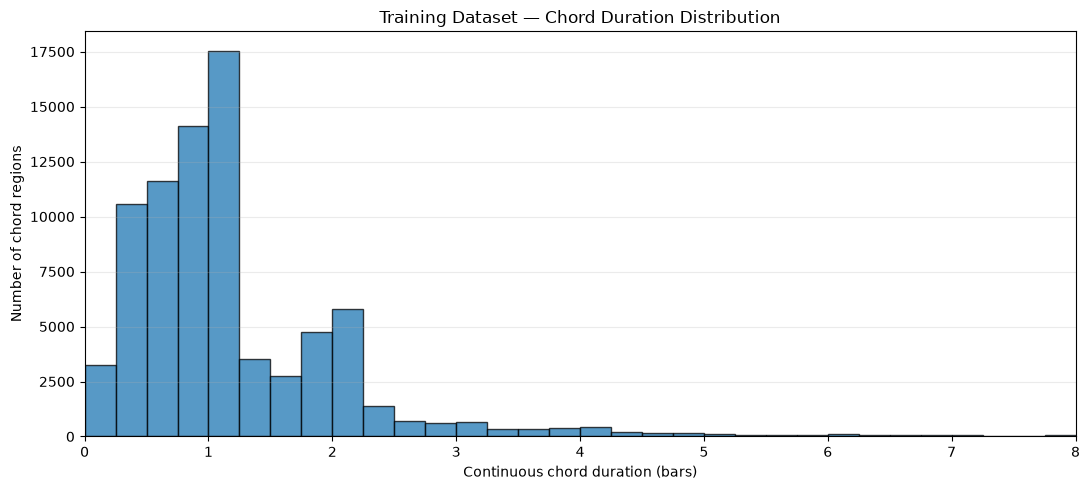


FINAL VERIFICATION
--------------------------------
Training/validation only: YES
Original dataset modified: NO
Filtering performed: NO
Test partition accessed: NO

Chord-duration analysis completed!


In [6]:
# ==========================================
# HARMONIC RHYTHM ANALYSIS
# CELL 6 — CHORD DURATION AND REGULARITY
# ==========================================

import numpy as np
import pandas as pd
from collections import defaultdict


# ==========================================
# 1. Convert a window into bar time intervals
# ==========================================

def get_bar_intervals(window):

    window_start = float(window["window_start_sec"])

    bars = defaultdict(list)

    for beat in window["beat_grid"]:

        start = window_start + float(beat["time_sec"])
        end = start + float(beat["duration_sec"])

        bars[int(beat["bar_index"])].append(
            (start, end)
        )

    intervals = []

    for bar_index in sorted(bars):

        beat_intervals = bars[bar_index]

        start = min(s for s, e in beat_intervals)
        end = max(e for s, e in beat_intervals)

        if end > start:

            intervals.append(
                (bar_index, start, end)
            )

    return intervals


# ==========================================
# 2. Convert a chord duration into bars
# ==========================================

def duration_in_bars(start, end, bar_intervals):

    total_bars = 0.0

    for bar_index, bar_start, bar_end in bar_intervals:

        overlap = max(
            0.0,
            min(end, bar_end) - max(start, bar_start)
        )

        bar_duration = bar_end - bar_start

        if bar_duration > 0:

            total_bars += overlap / bar_duration

    return total_bars


# ==========================================
# 3. Extract continuous chord regions
# ==========================================

def get_chord_regions(window):

    events = load_original_chords(
        window["track_id"]
    )

    if events is None:
        return []

    window_start = float(
        window["window_start_sec"]
    )

    window_end = (
        window_start
        + float(window["duration_sec"])
    )

    bar_intervals = get_bar_intervals(window)

    regions = []

    for event in events:

        start = max(
            window_start,
            event["start"]
        )

        end = min(
            window_end,
            event["end"]
        )

        if end <= start:
            continue

        label = str(
            event.get("label") or "N"
        )

        # Merge adjacent segments with identical
        # detailed chord labels.
        #
        # This prevents repeated identical events
        # from creating artificial chord changes.

        if (
            regions
            and regions[-1]["label"] == label
            and abs(start - regions[-1]["end"]) <= 0.001
        ):

            regions[-1]["end"] = max(
                end,
                regions[-1]["end"]
            )

        else:

            regions.append({
                "start": start,
                "end": end,
                "label": label
            })

    # Calculate duration and identify edge regions.

    for region in regions:

        region["duration_sec"] = (
            region["end"] - region["start"]
        )

        region["duration_bars"] = duration_in_bars(
            region["start"],
            region["end"],
            bar_intervals
        )

        region["is_chord"] = (
            region["label"].strip().upper()
            not in {"N", "NC", "N.C.", ""}
        )

        # An internal region does not touch the
        # beginning or end of the window.
        #
        # These regions are preferable when
        # measuring chord-duration regularity.

        region["is_internal"] = (
            region["start"] > window_start + 0.001
            and region["end"] < window_end - 0.001
        )

    return regions


# ==========================================
# 4. Analyze one window
# ==========================================

def analyze_event_harmonic_rhythm(window):

    regions = get_chord_regions(window)

    chord_regions = [
        r for r in regions
        if r["is_chord"]
    ]

    durations = np.array([
        r["duration_bars"]
        for r in chord_regions
    ])

    # Use complete internal chord regions
    # when estimating rhythmic regularity.

    internal_durations = np.array([
        r["duration_bars"]
        for r in chord_regions
        if r["is_internal"]
    ])

    # --------------------------------------
    # A. Chord changes
    # --------------------------------------

    chord_changes = 0
    all_label_changes = 0

    for previous, current in zip(
        regions[:-1],
        regions[1:]
    ):

        # Do not claim a precisely located
        # change across an annotation gap.

        contiguous = (
            abs(current["start"] - previous["end"])
            <= 0.02
        )

        different = (
            previous["label"] != current["label"]
        )

        if contiguous and different:

            all_label_changes += 1

            if (
                previous["is_chord"]
                and current["is_chord"]
            ):

                chord_changes += 1

    # --------------------------------------
    # B. Chord occupancy
    # --------------------------------------

    label_durations = defaultdict(float)

    for region in chord_regions:

        label_durations[
            region["label"]
        ] += region["duration_bars"]

    total_chord_bars = sum(
        label_durations.values()
    )

    dominant_share = (
        max(label_durations.values()) / total_chord_bars
        if total_chord_bars > 0
        else np.nan
    )

    # --------------------------------------
    # C. Harmonic-rhythm regularity
    # --------------------------------------

    # Coefficient of variation (CV):
    #
    # 0 means equal durations.
    # Larger values mean more variation.
    #
    # Require at least three internal regions.

    if (
        len(internal_durations) >= 3
        and internal_durations.mean() > 0
    ):

        duration_cv = (
            internal_durations.std()
            / internal_durations.mean()
        )

    else:

        duration_cv = np.nan

    # --------------------------------------
    # D. Summary
    # --------------------------------------

    return {

        "track_id": window["track_id"],
        "window_index": window["window_index"],
        "split": window["split"],

        "chord_regions": len(chord_regions),

        "chord_changes": chord_changes,

        "all_label_changes": all_label_changes,

        "changes_per_bar": chord_changes / 16,

        "mean_chord_bars": (
            durations.mean()
            if len(durations) else np.nan
        ),

        "median_chord_bars": (
            np.median(durations)
            if len(durations) else np.nan
        ),

        "longest_chord_bars": (
            durations.max()
            if len(durations) else np.nan
        ),

        "shortest_chord_bars": (
            durations.min()
            if len(durations) else np.nan
        ),

        "duration_cv": duration_cv,

        "internal_regions":
            len(internal_durations),

        "dominant_chord_share":
            dominant_share,

        "chord_coverage_bars":
            total_chord_bars,

        "no_chord_regions": (
            len(regions) - len(chord_regions)
        )
    }


# ==========================================
# 5. Analyze training and validation windows
# ==========================================

event_results = []

all_region_rows = []

for window in analysis_windows:

    result = analyze_event_harmonic_rhythm(
        window
    )

    event_results.append(result)

    regions = get_chord_regions(window)

    for region in regions:

        if not region["is_chord"]:
            continue

        all_region_rows.append({

            "split": window["split"],

            "track_id": window["track_id"],

            "window_index": window["window_index"],

            "chord": region["label"],

            "duration_sec":
                region["duration_sec"],

            "duration_bars":
                region["duration_bars"],

            "is_internal":
                region["is_internal"]
        })


harmonic_rhythm_df = pd.DataFrame(
    event_results
)

chord_regions_df = pd.DataFrame(
    all_region_rows
)


print("ORIGINAL-EVENT HARMONIC RHYTHM ANALYSIS")
print("--------------------------------")

print(
    "Windows analyzed:",
    len(harmonic_rhythm_df)
)

print(
    "Chord regions examined:",
    len(chord_regions_df)
)


# ==========================================
# 6. Overall harmonic-rhythm statistics
# ==========================================

summary = (
    harmonic_rhythm_df
    .groupby("split")
    .agg(

        windows=("track_id", "size"),

        mean_changes=(
            "chord_changes", "mean"
        ),

        median_changes=(
            "chord_changes", "median"
        ),

        mean_chord_duration=(
            "mean_chord_bars", "mean"
        ),

        median_chord_duration=(
            "median_chord_bars", "median"
        ),

        mean_longest_chord=(
            "longest_chord_bars", "mean"
        ),

        median_longest_chord=(
            "longest_chord_bars", "median"
        ),

        mean_duration_cv=(
            "duration_cv", "mean"
        ),

        mean_dominant_share=(
            "dominant_chord_share", "mean"
        )

    )
    .reset_index()
)

print("\nHARMONIC RHYTHM SUMMARY")
print("--------------------------------")

display(
    summary.round(3)
)


# ==========================================
# 7. Distribution of chord durations
# ==========================================

# Duration categories measured in bars.

duration_bins = [
    0, 0.5, 1, 2, 4, 6, np.inf
]

duration_labels = [
    "< 0.5 bar",
    "0.5–1 bar",
    "1–2 bars",
    "2–4 bars",
    "4–6 bars",
    "6+ bars"
]

chord_regions_df["duration_group"] = pd.cut(
    chord_regions_df["duration_bars"],
    bins=duration_bins,
    labels=duration_labels,
    right=False
)

duration_distribution = pd.crosstab(
    chord_regions_df["duration_group"],
    chord_regions_df["split"]
)

duration_distribution = (
    duration_distribution.reindex(
        duration_labels,
        fill_value=0
    )
)

print("\nCHORD DURATION DISTRIBUTION")
print("--------------------------------")

display(
    duration_distribution
)


# ==========================================
# 8. Long chord repetitions
# ==========================================

long_repetition_rows = []

for split in ["train", "val"]:

    subset = harmonic_rhythm_df[
        harmonic_rhythm_df["split"] == split
    ]

    long_repetition_rows.append({

        "Split": split,

        "Windows": len(subset),

        "Longest >= 2 bars":
            int(
                (
                    subset["longest_chord_bars"] >= 2
                ).sum()
            ),

        "Longest >= 4 bars":
            int(
                (
                    subset["longest_chord_bars"] >= 4
                ).sum()
            ),

        "Longest >= 6 bars":
            int(
                (
                    subset["longest_chord_bars"] >= 6
                ).sum()
            ),

        "Longest >= 8 bars":
            int(
                (
                    subset["longest_chord_bars"] >= 8
                ).sum()
            )
    })


long_repetition_df = pd.DataFrame(
    long_repetition_rows
)

print("\nWINDOWS CONTAINING LONG CHORD REGIONS")
print("--------------------------------")

display(
    long_repetition_df
)


# ==========================================
# 9. Regularity of harmonic rhythm
# ==========================================

regularity_summary = (
    harmonic_rhythm_df
    .groupby("split")["duration_cv"]
    .describe(
        percentiles=[0.25, 0.5, 0.75, 0.9]
    )
)

print("\nHARMONIC RHYTHM REGULARITY")
print("--------------------------------")

display(
    regularity_summary.round(3)
)

print(
    "\nCV interpretation:"
    "\n  CV near 0: similar chord durations"
    "\n  Larger CV: more variable durations"
    "\n  NaN: insufficient internal chord regions"
)


# ==========================================
# 10. Identify potentially static windows
# ==========================================

train_rhythm = harmonic_rhythm_df[
    harmonic_rhythm_df["split"] == "train"
]

static_candidates = (
    train_rhythm
    .sort_values(
        "longest_chord_bars",
        ascending=False
    )
)

print("\nLONGEST CONTINUOUS CHORD REGIONS")
print("--------------------------------")

display(
    static_candidates[
        [
            "track_id",
            "window_index",
            "chord_regions",
            "chord_changes",
            "mean_chord_bars",
            "longest_chord_bars",
            "dominant_chord_share",
            "duration_cv"
        ]
    ].head(20).round(3)
)


# ==========================================
# 11. Plot chord-duration distribution
# ==========================================

import matplotlib.pyplot as plt

train_durations = chord_regions_df[
    chord_regions_df["split"] == "train"
]

plt.figure(figsize=(11, 5))

plt.hist(
    train_durations["duration_bars"],
    bins=np.arange(0, 8.25, 0.25),
    edgecolor="black",
    alpha=0.75
)

plt.xlabel("Continuous chord duration (bars)")

plt.ylabel("Number of chord regions")

plt.title(
    "Training Dataset — Chord Duration Distribution"
)

plt.xlim(0, 8)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()
plt.show()


# ==========================================
# 12. Dataset integrity
# ==========================================

assert len(harmonic_rhythm_df) == 7687

assert set(
    harmonic_rhythm_df["split"]
) == {"train", "val"}

assert (
    harmonic_rhythm_df["longest_chord_bars"]
    .dropna()
    <= 16.01
).all()

print("\nFINAL VERIFICATION")
print("--------------------------------")

print("Training/validation only: YES")
print("Original dataset modified: NO")
print("Filtering performed: NO")
print("Test partition accessed: NO")

print("\nChord-duration analysis completed!")

### Visual Examination of Harmonic-Rhythm Patterns
Objective: Visualize representative 16-bar windows containing regular chord progressions, irregular chord durations, and unusually long chord repetitions.
Chord regions are plotted according to their original event timestamps and converted to musical bar positions using the existing beat grid.
Masked beat positions are overlaid to examine their relationship with harmonic changes.
Examples are selected from the training set only. The analysis does not modify any dataset records.

HARMONIC RHYTHM EXAMPLE CATEGORIES
--------------------------------
Regular candidates: 412
Irregular candidates: 526
Long-repetition candidates: 119

SELECTED WINDOWS
--------------------------------


,Category,Track,Window,Unique chords,Chord changes,Longest chord (bars),Duration CV,Dominant chord share
0,REGULAR PROGRESSION,track_0961137,2,5,16,1.10,0.044,0.443
1,IRREGULAR PROGRESSION,track_0766435,1,3,11,6.04,0.853,0.735
2,LONG CHORD REPETITION,track_1032157,4,5,6,10.02,0.151,0.627


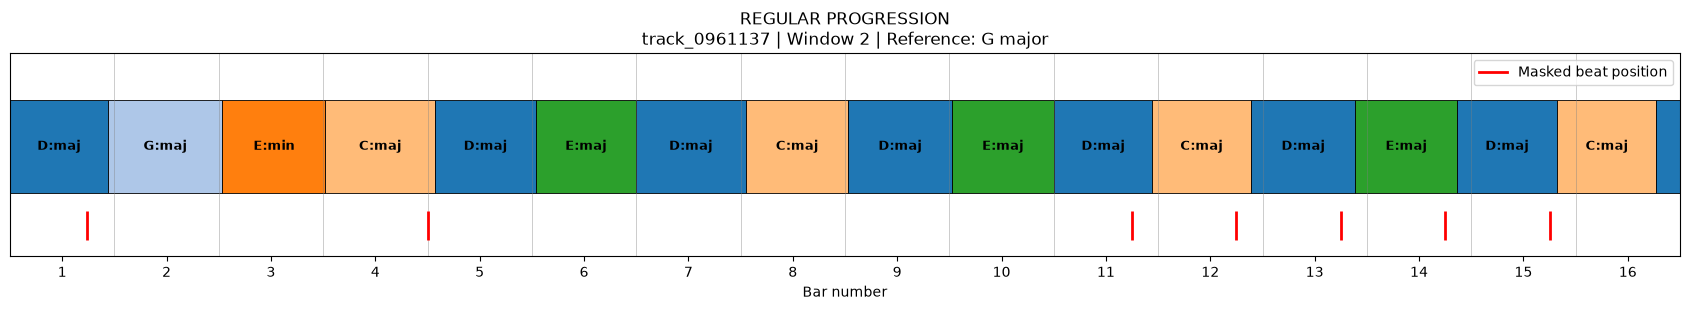

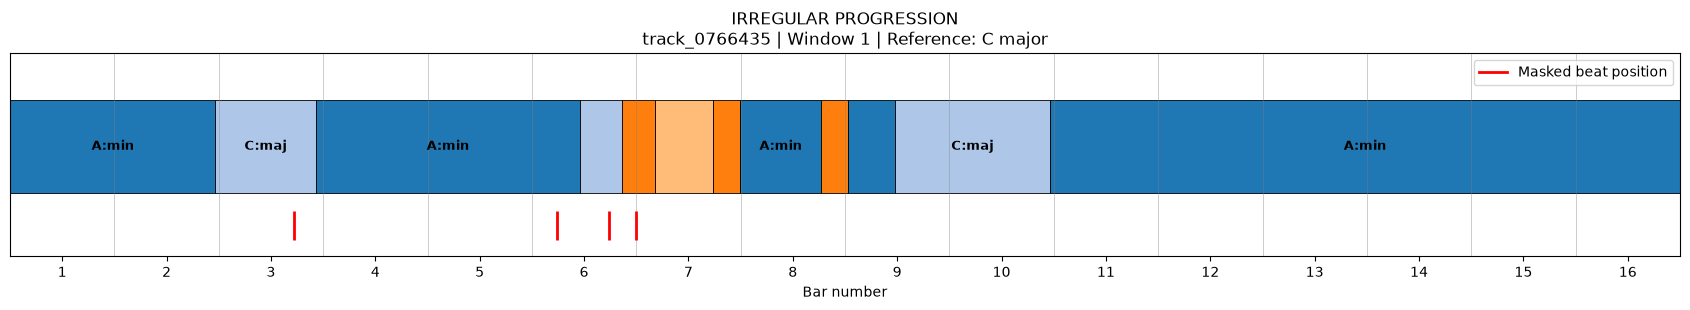

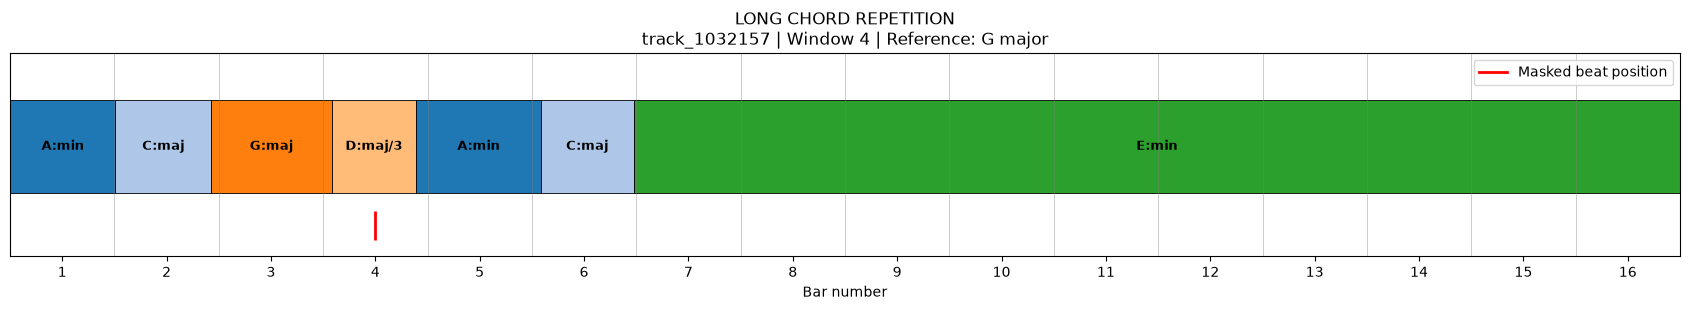


VISUALIZATION SUMMARY
--------------------------------
Examples displayed: 3
Source: Original timed chord events
Dataset split: TRAIN
Original dataset modified: NO
Filtering performed: NO
Test partition accessed: NO

Run this cell again for new examples.


In [7]:
# ==========================================
# HARMONIC RHYTHM ANALYSIS
# CELL 7 — VISUALIZE CHORD PROGRESSIONS
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D


# ==========================================
# 1. Combine previous analysis results
# ==========================================

overview = harmonic_rhythm_df.merge(
    chord_analysis_df[
        [
            "split",
            "track_id",
            "window_index",
            "unique_chords"
        ]
    ],
    on=["split", "track_id", "window_index"],
    how="left",
    validate="one_to_one"
)

train_overview = overview[
    overview["split"] == "train"
].copy()


# ==========================================
# 2. Define three harmonic-rhythm categories
# ==========================================

# A. Regular chord progressions:
# Many changes with similar chord durations.

regular_pool = train_overview[
    (train_overview["duration_cv"] <= 0.20)
    &
    (train_overview["chord_changes"] >= 10)
    &
    (train_overview["internal_regions"] >= 8)
    &
    (train_overview["longest_chord_bars"] < 2.5)
    &
    (train_overview["chord_coverage_bars"] >= 14)
]


# B. Irregular chord progressions:
# Considerable variation in chord durations.

irregular_pool = train_overview[
    (train_overview["duration_cv"] >= 0.80)
    &
    (train_overview["chord_changes"] >= 5)
    &
    (train_overview["internal_regions"] >= 5)
    &
    (train_overview["longest_chord_bars"] < 8)
]


# C. Long chord repetitions:
# A chord lasts at least eight bars.
# Prefer windows containing 4+ unique chords.

static_pool = train_overview[
    (train_overview["longest_chord_bars"] >= 8)
    &
    (train_overview["dominant_chord_share"] >= 0.60)
    &
    (train_overview["unique_chords"] >= 4)
]


print("HARMONIC RHYTHM EXAMPLE CATEGORIES")
print("--------------------------------")

print("Regular candidates:", len(regular_pool))
print("Irregular candidates:", len(irregular_pool))
print("Long-repetition candidates:", len(static_pool))


# ==========================================
# 3. Select random examples
# ==========================================

# Running the cell again selects new examples.

def choose_example(pool, fallback, name):

    if pool.empty:

        print(
            f"Warning: no strict {name} candidates. "
            "Using a relaxed selection."
        )

        pool = fallback

    if pool.empty:
        raise ValueError(
            f"No suitable examples for {name}"
        )

    return pool.sample(n=1).iloc[0]


examples = {
    "REGULAR PROGRESSION": choose_example(
        regular_pool,
        train_overview[
            train_overview["chord_changes"] >= 10
        ],
        "regular"
    ),

    "IRREGULAR PROGRESSION": choose_example(
        irregular_pool,
        train_overview[
            train_overview["duration_cv"].notna()
        ],
        "irregular"
    ),

    "LONG CHORD REPETITION": choose_example(
        static_pool,
        train_overview[
            train_overview["longest_chord_bars"] >= 8
        ],
        "long-repetition"
    )
}


# ==========================================
# 4. Build lookup for original windows
# ==========================================

window_lookup = {
    (w["track_id"], w["window_index"]): w
    for w in analysis_windows
}


# ==========================================
# 5. Convert absolute time to bar position
# ==========================================

def time_to_bar_position(time_sec, bar_intervals):

    if not bar_intervals:
        return 0.0

    first_bar, first_start, _ = bar_intervals[0]

    if time_sec <= first_start:
        return float(first_bar)

    for bar_index, start, end in bar_intervals:

        if time_sec < start:
            return float(bar_index)

        if start <= time_sec <= end:

            fraction = (
                (time_sec - start) / (end - start)
            )

            return bar_index + fraction

    return float(bar_intervals[-1][0] + 1)


# ==========================================
# 6. Plot a single 16-bar window
# ==========================================

def plot_chord_timeline(window, category):

    regions = get_chord_regions(window)

    bar_intervals = get_bar_intervals(window)

    fig, ax = plt.subplots(
        figsize=(17, 3.2)
    )

    # Assign a consistent color to each
    # different chord within this window.

    unique_labels = list(dict.fromkeys(
        region["label"] for region in regions
    ))

    cmap = plt.get_cmap("tab20")

    label_colors = {
        label: cmap(i % 20)
        for i, label in enumerate(unique_labels)
    }

    # --------------------------------------
    # A. Draw bar boundaries
    # --------------------------------------

    for bar in range(17):

        ax.axvline(
            bar,
            color="gray",
            linewidth=0.7,
            alpha=0.4
        )

    # --------------------------------------
    # B. Draw original chord regions
    # --------------------------------------

    for region in regions:

        x_start = time_to_bar_position(
            region["start"],
            bar_intervals
        )

        x_end = time_to_bar_position(
            region["end"],
            bar_intervals
        )

        width = max(0, x_end - x_start)

        if width <= 0:
            continue

        label = region["label"]

        ax.barh(
            y=0.5,
            width=width,
            left=x_start,
            height=0.55,
            color=label_colors[label],
            edgecolor="black",
            linewidth=0.6
        )

        # Only display text when there is
        # sufficient space inside the region.

        if width >= 0.60:

            ax.text(
                x_start + width / 2,
                0.5,
                label,
                ha="center",
                va="center",
                fontsize=9,
                fontweight="bold"
            )

    # --------------------------------------
    # C. Mark masked beat positions
    # --------------------------------------

    window_start = float(
        window["window_start_sec"]
    )

    masked_positions = []

    for beat, grid in zip(
        window["beat_targets"],
        window["beat_grid"]
    ):

        if beat.get("model_target_mask") == 1:
            continue

        absolute_time = (
            window_start
            + float(grid["time_sec"])
        )

        x = time_to_bar_position(
            absolute_time,
            bar_intervals
        )

        masked_positions.append(x)

    if masked_positions:

        ax.vlines(
            masked_positions,
            -0.05,
            0.12,
            color="red",
            linewidth=2
        )

    # --------------------------------------
    # D. Format chart
    # --------------------------------------

    ax.set_xlim(0, 16)
    ax.set_ylim(-0.15, 1.05)

    ax.set_xticks(
        np.arange(0.5, 16.5, 1)
    )

    ax.set_xticklabels(
        range(1, 17)
    )

    ax.set_yticks([])

    ax.set_xlabel("Bar number")

    ax.set_title(
        f"{category}\n"
        f"{window['track_id']} | "
        f"Window {window['window_index']} | "
        f"Reference: {window['reference_key']}"
    )

    ax.legend(
        handles=[
            Line2D(
                [0], [0],
                color="red",
                linewidth=2,
                label="Masked beat position"
            )
        ],
        loc="upper right"
    )

    plt.tight_layout()
    plt.show()


# ==========================================
# 7. Display selected examples
# ==========================================

selected_rows = []

for category, row in examples.items():

    track_id = row["track_id"]

    window_index = int(
        row["window_index"]
    )

    window = window_lookup[
        (track_id, window_index)
    ]

    selected_rows.append({

        "Category": category,

        "Track": track_id,

        "Window": window_index,

        "Unique chords":
            int(row["unique_chords"]),

        "Chord changes":
            int(row["chord_changes"]),

        "Longest chord (bars)":
            round(
                row["longest_chord_bars"], 2
            ),

        "Duration CV":
            round(
                row["duration_cv"], 3
            )
            if pd.notna(row["duration_cv"])
            else None,

        "Dominant chord share":
            round(
                row["dominant_chord_share"], 3
            )
    })


print("\nSELECTED WINDOWS")
print("--------------------------------")

display(
    pd.DataFrame(selected_rows)
)


for category, row in examples.items():

    window = window_lookup[
        (
            row["track_id"],
            int(row["window_index"])
        )
    ]

    plot_chord_timeline(
        window,
        category
    )


# ==========================================
# 8. Final verification
# ==========================================

print("\nVISUALIZATION SUMMARY")
print("--------------------------------")

print("Examples displayed:", len(examples))
print("Source: Original timed chord events")
print("Dataset split: TRAIN")

print("Original dataset modified: NO")
print("Filtering performed: NO")
print("Test partition accessed: NO")

print("\nRun this cell again for new examples.")

### Harmonic-Rhythm-Aware Training Window Filtering
Objective: Identify training windows dominated by excessively long or disproportionately sustained chords.
Continuous harmonic regions are reconstructed from the original Roman-numeral chord events using the seven-family representation.
Two filtering conditions are evaluated:
1. Remove windows containing any continuous chord region lasting six bars or longer.
2. Remove windows where the longest chord lasts at least four bars and is at least twice the median duration of the remaining chord regions.
Balanced progressions with consistently longer chord durations are preserved unless they violate the six-bar maximum.
The analysis reports the number of retained windows, removed songs, chord-family distribution changes, and representative filtering examples.
No dataset files are modified during this step.

In [8]:
# ==========================================
# HARMONIC RHYTHM ANALYSIS
# CELL 8 — TRAINING WINDOW FILTER PREVIEW
# ==========================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from functools import lru_cache
from collections import Counter


# ==========================================
# 1. Filtering configuration
# ==========================================

MAX_CHORD_BARS = 6.0

IMBALANCE_MIN_BARS = 4.0

MAX_DURATION_RATIO = 2.0

VALID_FAMILIES = {
    "MAJ", "MIN", "DOM",
    "DIM", "HDIM", "AUG", "SUS"
}

FAMILY_ALIASES = {
    "MAJOR": "MAJ",
    "MINOR": "MIN",
    "DOMINANT": "DOM",
    "DIMINISHED": "DIM",
    "HALF_DIMINISHED": "HDIM",
    "AUGMENTED": "AUG",
    "SUSPENDED": "SUS"
}


def normalize_family(value):

    if value is None:
        return None

    family = str(value).strip().upper()

    family = FAMILY_ALIASES.get(
        family, family
    )

    return (
        family
        if family in VALID_FAMILIES
        else None
    )


# ==========================================
# 2. Load original Roman chord events
# ==========================================

@lru_cache(maxsize=None)
def load_roman_events(track_id):

    path = (
        PIPELINE_OUTPUTS
        / track_id
        / "roman"
        / "submission.json"
    )

    if not path.exists():
        return None

    with open(path, "r") as file:
        data = json.load(file)

    events = data.get("events", [])

    return sorted(
        events,
        key=lambda e: float(e["start_sec"])
    )


# ==========================================
# 3. Convert events to model chord classes
# ==========================================

def roman_event_label(event):

    root = event.get(
        "relative_root_semitones"
    )

    family = normalize_family(
        event.get("family")
    )

    if root is None or family is None:
        return None

    return (
        int(root) % 12,
        family
    )


# ==========================================
# 4. Reconstruct continuous chord regions
# ==========================================

def get_model_chord_regions(window):

    events = load_roman_events(
        window["track_id"]
    )

    if events is None:
        raise FileNotFoundError(
            window["track_id"]
        )

    start_time = float(
        window["window_start_sec"]
    )

    end_time = (
        start_time
        + float(window["duration_sec"])
    )

    bar_intervals = get_bar_intervals(
        window
    )

    regions = []

    for event in events:

        start = max(
            start_time,
            float(event["start_sec"])
        )

        end = min(
            end_time,
            float(event["end_sec"])
        )

        if end <= start:
            continue

        label = roman_event_label(
            event
        )

        # Merge only adjacent regions
        # belonging to the same model class.
        #
        # Unknown / N.C. regions interrupt runs.

        if (
            regions
            and label is not None
            and regions[-1]["label"] == label
            and abs(
                start - regions[-1]["end"]
            ) <= 0.02
        ):

            regions[-1]["end"] = max(
                regions[-1]["end"],
                end
            )

        else:

            regions.append({
                "start": start,
                "end": end,
                "label": label
            })

    # Convert durations into musical bars.

    for region in regions:

        region["duration_bars"] = (
            duration_in_bars(
                region["start"],
                region["end"],
                bar_intervals
            )
        )

    return regions


# ==========================================
# 5. Evaluate filtering conditions
# ==========================================

def evaluate_harmonic_filter(window):

    regions = get_model_chord_regions(
        window
    )

    chord_regions = [
        r for r in regions
        if r["label"] is not None
    ]

    durations = sorted(
        [
            r["duration_bars"]
            for r in chord_regions
        ],
        reverse=True
    )

    if not durations:

        return {
            "max_duration": np.nan,
            "other_median": np.nan,
            "duration_ratio": np.nan,
            "chord_regions": 0,
            "chord_coverage_bars": 0.0,
            "unique_chords": 0,
            "remove_max": False,
            "remove_imbalance": False,
            "remove": False,
            "reason": "NO_MAPPED_CHORDS"
        }

    longest = durations[0]

    others = durations[1:]

    other_median = (
        float(np.median(others))
        if others
        else np.nan
    )

    ratio = (
        longest / other_median
        if others and other_median > 0
        else np.nan
    )

    # --------------------------------------
    # Condition A: Excessive duration
    # --------------------------------------

    remove_max = (
        longest >= MAX_CHORD_BARS
    )

    # --------------------------------------
    # Condition B: Duration imbalance
    # --------------------------------------

    remove_imbalance = (
        longest >= IMBALANCE_MIN_BARS
        and np.isfinite(ratio)
        and ratio >= MAX_DURATION_RATIO
    )

    remove = (
        remove_max or remove_imbalance
    )

    if remove_max and remove_imbalance:

        reason = "BOTH"

    elif remove_max:

        reason = "LONG_DURATION"

    elif remove_imbalance:

        reason = "DURATION_IMBALANCE"

    else:

        reason = "KEEP"

    return {
        "max_duration": longest,
        "other_median": other_median,
        "duration_ratio": ratio,

        "chord_regions": len(chord_regions),

        "chord_coverage_bars": sum(
            durations
        ),

        "unique_chords": len({
            r["label"]
            for r in chord_regions
        }),

        "remove_max": remove_max,

        "remove_imbalance": remove_imbalance,

        "remove": remove,

        "reason": reason
    }


# ==========================================
# 6. Analyze TRAINING windows only
# ==========================================

train_windows = [
    w for w in windows
    if w["split"] == "train"
]

assert len(train_windows) == 6282

filter_results = []

for window in train_windows:

    result = evaluate_harmonic_filter(
        window
    )

    filter_results.append({
        "track_id": window["track_id"],

        "artist_id": window.get(
            "artist_id"
        ),

        "window_index":
            window["window_index"],

        **result
    })


filter_preview_df = pd.DataFrame(
    filter_results
)


# ==========================================
# 7. Overall filtering results
# ==========================================

original_count = len(
    filter_preview_df
)

removed_count = int(
    filter_preview_df["remove"].sum()
)

retained_count = (
    original_count - removed_count
)

print("HARMONIC-RHYTHM FILTER PREVIEW")
print("--------------------------------")

print(
    "Original training windows:",
    original_count
)

print(
    "Windows to remove:",
    removed_count
)

print(
    "Windows to retain:",
    retained_count
)

print(
    "Training data retained:",
    f"{retained_count / original_count:.2%}"
)


# ==========================================
# 8. Filtering reasons
# ==========================================

print("\nFILTERING REASONS")
print("--------------------------------")

reason_counts = (
    filter_preview_df["reason"]
    .value_counts()
    .rename_axis("Reason")
    .reset_index(name="Windows")
)

display(reason_counts)


# ==========================================
# 9. Song and artist retention
# ==========================================

retained_df = filter_preview_df[
    ~filter_preview_df["remove"]
]

original_songs = set(
    filter_preview_df["track_id"]
)

retained_songs = set(
    retained_df["track_id"]
)

original_artists = set(
    filter_preview_df["artist_id"].dropna()
)

retained_artists = set(
    retained_df["artist_id"].dropna()
)

print("\nSONG AND ARTIST RETENTION")
print("--------------------------------")

print(
    "Original songs:",
    len(original_songs)
)

print(
    "Retained songs:",
    len(retained_songs)
)

print(
    "Songs completely removed:",
    len(original_songs - retained_songs)
)

print(
    "Original artists:",
    len(original_artists)
)

print(
    "Retained artists:",
    len(retained_artists)
)

print(
    "Artists completely removed:",
    len(original_artists - retained_artists)
)


# ==========================================
# 10. Compare chord-family distributions
# ==========================================

# Count reliable training beat targets.
#
# This measures how filtering changes the
# distribution of supervised chord labels.

retained_keys = {
    (row["track_id"], int(row["window_index"]))
    for _, row in retained_df.iterrows()
}

before_families = Counter()
after_families = Counter()

for window in train_windows:

    key = (
        window["track_id"],
        int(window["window_index"])
    )

    for beat in window["beat_targets"]:

        if beat.get("model_target_mask") != 1:
            continue

        family = normalize_family(
            beat.get("family")
        )

        if family is None:
            continue

        before_families[family] += 1

        if key in retained_keys:
            after_families[family] += 1


family_rows = []

for family in sorted(VALID_FAMILIES):

    before = before_families[family]
    after = after_families[family]

    total_before = sum(
        before_families.values()
    )

    total_after = sum(
        after_families.values()
    )

    family_rows.append({
        "Family": family,

        "Before": before,

        "After": after,

        "Before %": (
            100 * before / total_before
            if total_before else 0
        ),

        "After %": (
            100 * after / total_after
            if total_after else 0
        )
    })


family_distribution_df = pd.DataFrame(
    family_rows
)

print("\nCHORD-FAMILY DISTRIBUTION")
print("--------------------------------")

display(
    family_distribution_df.round(2)
)


# ==========================================
# 11. Inspect removed windows
# ==========================================

removed_examples = (
    filter_preview_df[
        filter_preview_df["remove"]
    ]
    .sort_values(
        "max_duration",
        ascending=False
    )
)

print("\nEXAMPLES MARKED FOR REMOVAL")
print("--------------------------------")

display(
    removed_examples[
        [
            "track_id",
            "window_index",
            "unique_chords",
            "chord_regions",
            "max_duration",
            "other_median",
            "duration_ratio",
            "reason"
        ]
    ].head(15).round(3)
)


# ==========================================
# 12. Inspect retained longer progressions
# ==========================================

balanced_examples = (
    retained_df[
        retained_df["max_duration"] >= 3.5
    ]
    .sort_values(
        "max_duration",
        ascending=False
    )
)

print("\nLONG BUT RETAINED PROGRESSIONS")
print("--------------------------------")

display(
    balanced_examples[
        [
            "track_id",
            "window_index",
            "unique_chords",
            "chord_regions",
            "max_duration",
            "other_median",
            "duration_ratio"
        ]
    ].head(15).round(3)
)


# ==========================================
# 13. Final verification
# ==========================================

assert (
    retained_count + removed_count
    == original_count
)

assert set(
    filter_preview_df["reason"]
) <= {
    "KEEP",
    "LONG_DURATION",
    "DURATION_IMBALANCE",
    "BOTH",
    "NO_MAPPED_CHORDS"
}

assert len(train_windows) == 6282

print("\nFINAL VERIFICATION")
print("--------------------------------")

print("Train windows evaluated:", 6282)

print("Validation windows modified: NO")
print("Test windows accessed: NO")

print("Dataset files modified: NO")
print("Filtering preview completed: YES")

HARMONIC-RHYTHM FILTER PREVIEW
--------------------------------
Original training windows: 6282
Windows to remove: 1754
Windows to retain: 4528
Training data retained: 72.08%

FILTERING REASONS
--------------------------------


,Reason,Windows
0,KEEP,4523
1,DURATION_IMBALANCE,879
2,BOTH,854
3,LONG_DURATION,21
4,NO_MAPPED_CHORDS,5



SONG AND ARTIST RETENTION
--------------------------------
Original songs: 752
Retained songs: 701
Songs completely removed: 51
Original artists: 152
Retained artists: 148
Artists completely removed: 4

CHORD-FAMILY DISTRIBUTION
--------------------------------


,Family,Before,After,Before %,After %
0,AUG,76,68,0.02,0.03
1,DIM,484,385,0.15,0.16
2,DOM,11193,10033,3.36,4.18
3,HDIM,213,184,0.06,0.08
4,MAJ,183504,138730,55.16,57.83
5,MIN,136160,89650,40.93,37.37
6,SUS,1040,844,0.31,0.35



EXAMPLES MARKED FOR REMOVAL
--------------------------------


,track_id,window_index,unique_chords,chord_regions,max_duration,other_median,duration_ratio,reason
3291,track_1076457,0,3,3,15.504,0.248,62.538,BOTH
4723,track_1134854,18,3,3,15.245,0.378,40.372,BOTH
5777,track_1168474,1,1,2,15.086,0.478,31.535,BOTH
6134,track_1294933,1,1,2,15.086,0.478,31.535,BOTH
5507,track_1160052,9,3,3,14.958,0.521,28.720,BOTH
5892,track_1169062,6,3,3,14.865,0.568,26.183,BOTH
6188,track_1320939,3,2,3,14.850,0.575,25.826,BOTH
868,track_0500420,5,3,3,14.799,0.601,24.636,BOTH
3680,track_1095021,0,3,3,14.778,0.604,24.456,BOTH
786,track_0500411,11,3,3,14.679,0.661,22.216,BOTH



LONG BUT RETAINED PROGRESSIONS
--------------------------------


,track_id,window_index,unique_chords,chord_regions,max_duration,other_median,duration_ratio
2446,track_1041564,11,4,4,5.945,3.438,1.730
4713,track_1134854,6,3,3,5.861,4.168,1.406
5753,track_1163893,5,3,4,5.687,3.437,1.655
5544,track_1160057,1,3,4,5.599,3.784,1.480
1496,track_0878931,14,4,5,5.198,3.469,1.498
3155,track_1075135,2,3,4,5.169,4.206,1.229
1503,track_0878931,32,5,5,5.156,2.708,1.904
3126,track_1072573,9,3,6,5.063,3.297,1.536
2438,track_1041564,0,2,3,5.059,4.477,1.130
2071,track_1030654,2,3,4,5.027,4.000,1.257



FINAL VERIFICATION
--------------------------------
Train windows evaluated: 6282
Validation windows modified: NO
Test windows accessed: NO
Dataset files modified: NO
Filtering preview completed: YES


### Event-Aware Chord and Harmonic-Change Supervision
Objective: Evaluate improved beat-level chord supervision using original timed Roman-numeral chord events.
A chord target is assigned when a single root–family chord occupies at least 80% of a beat. Otherwise, its chord-classification target remains masked.
Harmonic-change labels are calculated independently from the original chord-event boundaries.
The analysis measures recovered chord targets, newly masked targets, label agreement, and available transition supervision.
Only the 4,523 retained training windows are considered for future training. Validation windows are analyzed diagnostically without changing their existing targets. The test partition is not accessed.
No dataset files are modified.

In [9]:
# ==========================================
# HARMONIC RHYTHM ANALYSIS
# CELL 9 — EVENT-AWARE SUPERVISION PREVIEW
# ==========================================

import numpy as np
import pandas as pd
from collections import Counter, defaultdict


# ==========================================
# 1. Configuration
# ==========================================

HARD_CHORD_THRESHOLD = 0.80

MIN_CHANGE_COVERAGE = 0.98

# Use only explicitly retained training windows.
# The 5 windows without mapped chords are excluded.

keep_rows = filter_preview_df[
    filter_preview_df["reason"] == "KEEP"
]

keep_keys = set(
    zip(
        keep_rows["track_id"],
        keep_rows["window_index"].astype(int)
    )
)

selected_windows = [
    w for w in analysis_windows
    if (
        w["split"] == "val"
        or (
            w["split"] == "train"
            and (
                w["track_id"],
                int(w["window_index"])
            ) in keep_keys
        )
    )
]

assert len(keep_keys) == 4523
assert len(selected_windows) == 4523 + 1405


# ==========================================
# 2. Build event-aware targets for one window
# ==========================================

def build_event_aware_targets(window):

    regions = get_model_chord_regions(window)

    window_start = float(
        window["window_start_sec"]
    )

    # Find boundaries where two known
    # root-family chord labels differ.
    #
    # Unknown/N.C. regions do not produce
    # a confirmed chord-to-chord transition.

    change_times = []

    for previous, current in zip(
        regions[:-1],
        regions[1:]
    ):

        if (
            previous["label"] is not None
            and current["label"] is not None
            and previous["label"] != current["label"]
            and abs(
                previous["end"] - current["start"]
            ) <= 0.02
        ):

            change_times.append(
                current["start"]
            )

    results = []

    for i, (beat, grid) in enumerate(
        zip(
            window["beat_targets"],
            window["beat_grid"]
        )
    ):

        start = (
            window_start
            + float(grid["time_sec"])
        )

        end = (
            start
            + float(grid["duration_sec"])
        )

        beat_duration = end - start

        if beat_duration <= 0:
            raise ValueError(
                "Nonpositive beat duration: "
                f"{window['track_id']}, beat {i}"
            )

        # ----------------------------------
        # A. Chord occupancy
        # ----------------------------------

        chord_overlap = defaultdict(float)

        mapped_coverage = 0.0

        for region in regions:

            overlap = max(
                0.0,
                min(end, region["end"])
                - max(start, region["start"])
            )

            if overlap <= 0:
                continue

            label = region["label"]

            if label is not None:

                chord_overlap[label] += overlap

                mapped_coverage += overlap

        if chord_overlap:

            best_label = max(
                chord_overlap,
                key=chord_overlap.get
            )

            best_share = (
                chord_overlap[best_label]
                / beat_duration
            )

        else:

            best_label = None
            best_share = 0.0

        coverage_share = min(
            1.0,
            mapped_coverage / beat_duration
        )

        # ----------------------------------
        # B. Hard chord supervision
        # ----------------------------------

        new_chord_valid = (
            best_label is not None
            and best_share >= HARD_CHORD_THRESHOLD
        )

        if new_chord_valid:

            new_root = best_label[0]
            new_family = best_label[1]

        else:

            new_root = None
            new_family = None

        # ----------------------------------
        # C. Chord-change supervision
        # ----------------------------------

        # A boundary exactly at the start of
        # a beat belongs to that beat.
        #
        # A boundary at its end belongs to
        # the following beat.
        #
        # The first beat is not assigned a
        # negative label unless a positive
        # within-beat change is observed.

        has_change = any(
            start - 1e-6 <= t < end - 1e-6
            for t in change_times
        )

        # Negative change labels require
        # near-complete coverage by known
        # mapped chord events.
        #
        # Positive labels can still be used
        # when a known chord change exists.

        change_valid = (
            has_change
            or (
                coverage_share >= MIN_CHANGE_COVERAGE
                and i > 0
            )
        )

        # ----------------------------------
        # D. Existing reliable targets
        # ----------------------------------

        old_valid = (
            beat.get("model_target_mask") == 1
            and beat.get("root_id") is not None
            and beat.get("family_id") is not None
        )

        old_label = None

        if old_valid:

            old_label = (
                int(beat["root_id"]),
                normalize_family(
                    beat.get("family")
                )
            )

        # ----------------------------------
        # E. Store proposed supervision
        # ----------------------------------

        results.append({

            "beat_index": i,

            "old_valid": bool(old_valid),

            "old_label": old_label,

            "old_target_state":
                beat.get("target_state"),

            "new_valid": bool(new_chord_valid),

            "new_label": (
                (new_root, new_family)
                if new_chord_valid
                else None
            ),

            "chord_occupancy":
                float(best_share),

            "mapped_coverage":
                float(coverage_share),

            "change_label":
                int(has_change)
                if change_valid
                else None,

            "change_valid":
                bool(change_valid)

        })

    return results


# ==========================================
# 3. Process selected windows
# ==========================================

event_aware_train_targets = {}

summary_counters = {
    "train": Counter(),
    "val": Counter()
}

rescued_examples = []

for window in selected_windows:

    split = window["split"]

    targets = build_event_aware_targets(
        window
    )

    if split == "train":

        key = (
            window["track_id"],
            int(window["window_index"])
        )

        event_aware_train_targets[key] = targets

    counts = summary_counters[split]

    counts["windows"] += 1

    for target in targets:

        counts["beats"] += 1

        old_valid = target["old_valid"]
        new_valid = target["new_valid"]

        counts["old_valid"] += int(old_valid)
        counts["new_valid"] += int(new_valid)

        if new_valid and not old_valid:

            counts["recovered"] += 1

            if (
                split == "train"
                and len(rescued_examples) < 12
            ):

                rescued_examples.append({

                    "Track": window["track_id"],

                    "Window":
                        window["window_index"],

                    "Beat":
                        target["beat_index"] + 1,

                    "Old state":
                        target["old_target_state"],

                    "New chord":
                        target["new_label"],

                    "Occupancy":
                        target["chord_occupancy"],

                    "Change":
                        target["change_label"]
                })

        if old_valid and not new_valid:
            counts["lost"] += 1

        if old_valid and new_valid:

            counts["overlap"] += 1

            if (
                target["old_label"]
                == target["new_label"]
            ):

                counts["agreement"] += 1

        if target["change_valid"]:

            counts["change_supervised"] += 1

            if target["change_label"] == 1:

                counts["change_positive"] += 1

                if not new_valid:
                    counts["change_only"] += 1

            else:

                counts["change_negative"] += 1

        else:

            counts["change_masked"] += 1


# ==========================================
# 4. Summarize new chord supervision
# ==========================================

rows = []

for split in ["train", "val"]:

    c = summary_counters[split]

    overlap = c["overlap"]

    rows.append({

        "Split": split,

        "Windows": c["windows"],

        "Old valid beats":
            c["old_valid"],

        "New valid beats":
            c["new_valid"],

        "Recovered beats":
            c["recovered"],

        "Newly masked beats":
            c["lost"],

        "Old/new agreement":
            (
                c["agreement"] / overlap
                if overlap else np.nan
            )
    })


supervision_summary_df = pd.DataFrame(
    rows
)

print("EVENT-AWARE CHORD SUPERVISION")
print("--------------------------------")

display(
    supervision_summary_df.round(4)
)


# ==========================================
# 5. Summarize change supervision
# ==========================================

change_rows = []

for split in ["train", "val"]:

    c = summary_counters[split]

    change_rows.append({

        "Split": split,

        "Total beats": c["beats"],

        "Change positives":
            c["change_positive"],

        "Change negatives":
            c["change_negative"],

        "Change masked":
            c["change_masked"],

        "Positive without hard chord":
            c["change_only"],

        "Change supervision coverage":
            (
                c["change_supervised"] / c["beats"]
                if c["beats"] else np.nan
            )
    })


change_supervision_df = pd.DataFrame(
    change_rows
)

print("\nHARMONIC-CHANGE SUPERVISION")
print("--------------------------------")

display(
    change_supervision_df.round(4)
)


# ==========================================
# 6. Inspect recovered chord labels
# ==========================================

print("\nEXAMPLES OF RECOVERED CHORD LABELS")
print("--------------------------------")

display(
    pd.DataFrame(
        rescued_examples
    ).round(3)
)


# ==========================================
# 7. Integrity checks
# ==========================================

assert len(event_aware_train_targets) == 4523

assert summary_counters["train"]["windows"] == 4523
assert summary_counters["val"]["windows"] == 1405

for split in ["train", "val"]:

    c = summary_counters[split]

    assert (
        c["change_positive"]
        + c["change_negative"]
        + c["change_masked"]
        == c["beats"]
    )

    assert c["agreement"] <= c["overlap"]

print("\nFINAL VERIFICATION")
print("--------------------------------")

print("Filtered training windows:", 4523)

print("Original dataset modified: NO")
print("Validation targets modified: NO")
print("Test partition accessed: NO")

print("New supervision saved in memory: YES")
print("Dataset file created: NO")

print("\nEvent-aware supervision preview complete!")

EVENT-AWARE CHORD SUPERVISION
--------------------------------


,Split,Windows,Old valid beats,New valid beats,Recovered beats,Newly masked beats,Old/new agreement
0,train,4523,239602,229008,220,10814,0.2790
1,val,1405,77718,75464,79,2333,0.1481



HARMONIC-CHANGE SUPERVISION
--------------------------------


,Split,Total beats,Change positives,Change negatives,Change masked,Positive without hard chord,Change supervision coverage
0,train,272175,54422,198800,18953,28359,0.9304
1,val,86624,14615,67244,4765,7621,0.9450



EXAMPLES OF RECOVERED CHORD LABELS
--------------------------------


,Track,Window,Beat,Old state,New chord,Occupancy,Change
0,track_0000388,2,41,MASK,"(9, MIN)",0.8,1
1,track_0000388,3,19,MASK,"(4, MAJ)",0.8,1
2,track_0021982,2,44,MASK,"(3, MAJ)",0.8,1
3,track_0021982,3,12,MASK,"(3, MAJ)",0.8,1
4,track_0031431,0,37,MASK,"(5, MAJ)",0.8,1
5,track_0031433,1,46,MASK,"(2, MAJ)",0.8,1
6,track_0043886,2,37,MASK,"(5, MAJ)",0.8,1
7,track_0046037,3,48,MASK,"(0, MIN)",0.8,1
8,track_0047050,7,27,MASK,"(5, MIN)",0.8,1
9,track_0047052,4,12,MASK,"(0, MIN)",0.8,1



FINAL VERIFICATION
--------------------------------
Filtered training windows: 4523
Original dataset modified: NO
Validation targets modified: NO
Test partition accessed: NO
New supervision saved in memory: YES
Dataset file created: NO

Event-aware supervision preview complete!


### Chord-Label Consistency Diagnosis
Objective: Investigate the unexpectedly low agreement between original beat-level chord targets and event-derived chord targets.
Root and family agreement will be measured separately, and the original family names and IDs will be compared against the newly generated labels.
This diagnostic will help distinguish genuine annotation differences from inconsistent chord-family representations or implementation errors.
No dataset modifications will be performed.

In [10]:
# ==========================================
# HARMONIC RHYTHM ANALYSIS
# CELL 9A — CHORD FAMILY MISMATCH DIAGNOSIS
# ==========================================

import random
import pandas as pd


# ==========================================
# 1. Select reproducible diagnostic sample
# ==========================================

rng = random.Random(42)

train_sample = rng.sample(
    [
        w for w in selected_windows
        if w["split"] == "train"
    ],
    100
)

val_sample = rng.sample(
    [
        w for w in selected_windows
        if w["split"] == "val"
    ],
    100
)

sample_windows = train_sample + val_sample


# ==========================================
# 2. Compare individual chord components
# ==========================================

diagnostic_rows = []

for window in sample_windows:

    targets = build_event_aware_targets(window)

    for beat, target in zip(
        window["beat_targets"],
        targets
    ):

        if not (
            target["old_valid"]
            and target["new_valid"]
        ):
            continue

        old_root, old_family = target["old_label"]
        new_root, new_family = target["new_label"]

        diagnostic_rows.append({

            "Split": window["split"],

            "Track": window["track_id"],

            "Beat": target["beat_index"] + 1,

            "Old root": old_root,
            "New root": new_root,

            "Old family raw":
                str(beat.get("family")),

            "Old family normalized":
                str(old_family),

            "Old family ID":
                beat.get("family_id"),

            "New family":
                str(new_family),

            "Root match":
                old_root == new_root,

            "Family match":
                old_family == new_family,

            "Joint match":
                (
                    old_root == new_root
                    and old_family == new_family
                ),

            "Old plan label":
                beat.get("plan_label"),

            "New label":
                f"{new_root}:{new_family}",

            "Occupancy":
                target["chord_occupancy"]
        })


diagnostic_df = pd.DataFrame(
    diagnostic_rows
)


# ==========================================
# 3. Independent agreement scores
# ==========================================

print("CHORD-LABEL CONSISTENCY DIAGNOSIS")
print("--------------------------------")

print(
    "Windows sampled:",
    len(sample_windows)
)

print(
    "Comparable beats:",
    len(diagnostic_df)
)

print("\nROOT VS FAMILY AGREEMENT")
print("--------------------------------")

agreement = (
    diagnostic_df
    .groupby("Split")[
        [
            "Root match",
            "Family match",
            "Joint match"
        ]
    ]
    .mean()
)

display(
    (agreement * 100).round(2)
)


# ==========================================
# 4. Original family values
# ==========================================

print("\nORIGINAL FAMILY REPRESENTATIONS")
print("--------------------------------")

family_values = (
    diagnostic_df[
        [
            "Old family raw",
            "Old family normalized",
            "Old family ID"
        ]
    ]
    .value_counts(dropna=False)
    .reset_index(name="Count")
)

display(
    family_values.head(25)
)


# ==========================================
# 5. Old vs new family comparison
# ==========================================

print("\nOLD VS NEW FAMILY LABELS")
print("--------------------------------")

family_comparison = pd.crosstab(
    diagnostic_df["Old family raw"],
    diagnostic_df["New family"]
)

display(family_comparison)


# ==========================================
# 6. Family ID vs new family
# ==========================================

print("\nOLD FAMILY ID VS NEW FAMILY")
print("--------------------------------")

id_comparison = pd.crosstab(
    diagnostic_df["Old family ID"],
    diagnostic_df["New family"]
)

display(id_comparison)


# ==========================================
# 7. Inspect mismatching predictions
# ==========================================

mismatches = diagnostic_df[
    ~diagnostic_df["Joint match"]
]

print("\nACTUAL MISMATCH EXAMPLES")
print("--------------------------------")

print(
    "Mismatching beats:",
    len(mismatches)
)

display(
    mismatches[
        [
            "Split",
            "Track",
            "Beat",
            "Old root",
            "New root",
            "Old family raw",
            "Old family ID",
            "New family",
            "Old plan label",
            "New label",
            "Occupancy"
        ]
    ].head(20)
)


# ==========================================
# 8. Verification
# ==========================================

print("\nFINAL VERIFICATION")
print("--------------------------------")

print("Dataset modified: NO")
print("New dataset created: NO")
print("Test partition accessed: NO")

print("\nDiagnosis completed!")

CHORD-LABEL CONSISTENCY DIAGNOSIS
--------------------------------
Windows sampled: 200
Comparable beats: 10638

ROOT VS FAMILY AGREEMENT
--------------------------------


,Root match,Family match,Joint match
Split,,,
train,30.57,100.0,30.57
val,11.78,100.0,11.78



ORIGINAL FAMILY REPRESENTATIONS
--------------------------------


,Old family raw,Old family normalized,Old family ID,Count
0,MAJ,MAJ,0,6283
1,MIN,MIN,1,4351
2,DIM,DIM,3,4



OLD VS NEW FAMILY LABELS
--------------------------------


...


OLD FAMILY ID VS NEW FAMILY
--------------------------------


New family,DIM,MAJ,MIN
Old family ID,,,
0,0,6283,0
1,0,0,4351
3,4,0,0



ACTUAL MISMATCH EXAMPLES
--------------------------------
Mismatching beats: 8416


,Split,Track,Beat,Old root,New root,Old family raw,Old family ID,New family,Old plan label,New label,Occupancy
0,train,track_0766434,2,4,0,MIN,1,MIN,III:MIN,0:MIN,1.000000
1,train,track_0766434,4,10,6,MAJ,0,MAJ,♭VII:MAJ,6:MAJ,1.000000
2,train,track_0766434,6,7,3,MAJ,0,MAJ,V:MAJ,3:MAJ,1.000000
3,train,track_0766434,7,7,3,MAJ,0,MAJ,V:MAJ,3:MAJ,1.000000
4,train,track_0766434,8,7,3,MAJ,0,MAJ,V:MAJ,3:MAJ,1.000000
5,train,track_0766434,10,4,0,MIN,1,MIN,III:MIN,0:MIN,1.000000
6,train,track_0766434,11,10,6,MAJ,0,MAJ,♭VII:MAJ,6:MAJ,0.846154
7,train,track_0766434,12,10,6,MAJ,0,MAJ,♭VII:MAJ,6:MAJ,1.000000
8,train,track_0766434,13,2,10,MIN,1,MIN,II:MIN,10:MIN,0.955556
9,train,track_0766434,14,2,10,MIN,1,MIN,II:MIN,10:MIN,1.000000



FINAL VERIFICATION
--------------------------------
Dataset modified: NO
New dataset created: NO
Test partition accessed: NO

Diagnosis completed!


### Corrected Roman-Numeral Root Normalization
Objective: Correct the reference-key mismatch identified in Cell 9A.
Relative chord roots will be calculated from original absolute chord names and each window's reference key. Chord families and original timing information remain unchanged.
The corrected chord regions will be used to verify previous filtering decisions and recompute event-aware label agreement.
The analysis excludes the test partition and does not modify the original dataset.

In [11]:
# ==========================================
# HARMONIC RHYTHM ANALYSIS
# CELL 9B — FIX ROOT NORMALIZATION
# ==========================================

import numpy as np
import pandas as pd
from collections import Counter


# ==========================================
# 1. Correct event root normalization
# ==========================================

def corrected_roman_event_label(event, window):

    # Example: "G:maj" -> "G"

    absolute_chord = event.get(
        "original_chord_label"
    )

    if absolute_chord is None:
        return None

    root_name = str(
        absolute_chord
    ).split(":")[0].strip()

    absolute_pc = note_to_pc(
        root_name
    )

    family = normalize_family(
        event.get("family")
    )

    key_pc = reference_key_pc(
        window
    )

    if (
        absolute_pc is None
        or family is None
        or key_pc is None
    ):
        return None

    # IMPORTANT:
    # Use the WINDOW reference key,
    # matching our prepared dataset.

    relative_root = (
        absolute_pc - key_pc
    ) % 12

    return (
        relative_root,
        family
    )


# ==========================================
# 2. Replace chord-region reconstruction
# ==========================================

def get_model_chord_regions(window):

    events = load_roman_events(
        window["track_id"]
    )

    if events is None:
        raise FileNotFoundError(
            window["track_id"]
        )

    window_start = float(
        window["window_start_sec"]
    )

    window_end = (
        window_start
        + float(window["duration_sec"])
    )

    bar_intervals = get_bar_intervals(
        window
    )

    regions = []

    for event in events:

        start = max(
            window_start,
            float(event["start_sec"])
        )

        end = min(
            window_end,
            float(event["end_sec"])
        )

        if end <= start:
            continue

        label = corrected_roman_event_label(
            event, window
        )

        # Merge adjacent identical
        # root-family chords.

        if (
            regions
            and label is not None
            and regions[-1]["label"] == label
            and abs(
                start - regions[-1]["end"]
            ) <= 0.02
        ):

            regions[-1]["end"] = max(
                regions[-1]["end"],
                end
            )

        else:

            regions.append({
                "start": start,
                "end": end,
                "label": label
            })

    for region in regions:

        region["duration_bars"] = (
            duration_in_bars(
                region["start"],
                region["end"],
                bar_intervals
            )
        )

    return regions


# ==========================================
# 3. Verify original filtering decisions
# ==========================================

old_filter = filter_preview_df.set_index(
    ["track_id", "window_index"]
)

new_filter_rows = []

changed_decisions = []

for window in train_windows:

    key = (
        window["track_id"],
        int(window["window_index"])
    )

    result = evaluate_harmonic_filter(
        window
    )

    old_reason = old_filter.loc[
        key, "reason"
    ]

    if result["reason"] != old_reason:

        changed_decisions.append({
            "Track": key[0],
            "Window": key[1],
            "Old": old_reason,
            "New": result["reason"]
        })

    new_filter_rows.append({
        "track_id": key[0],
        "artist_id": window.get("artist_id"),
        "window_index": key[1],
        **result
    })


# Update the in-memory preview only.
# No JSONL file is written.

filter_preview_df = pd.DataFrame(
    new_filter_rows
)

print("CORRECTED FILTER VERIFICATION")
print("--------------------------------")

print(
    "Training windows:",
    len(filter_preview_df)
)

print(
    "Changed filtering decisions:",
    len(changed_decisions)
)

print("\nCorrected filtering reasons:")

display(
    filter_preview_df["reason"]
    .value_counts()
    .rename_axis("Reason")
    .reset_index(name="Windows")
)

if changed_decisions:

    print("\nChanged examples:")

    display(
        pd.DataFrame(
            changed_decisions
        ).head(15)
    )


# ==========================================
# 4. Rebuild selected-window lookup
# ==========================================

keep_rows = filter_preview_df[
    filter_preview_df["reason"] == "KEEP"
]

keep_keys = set(
    zip(
        keep_rows["track_id"],
        keep_rows["window_index"].astype(int)
    )
)

selected_windows = [
    w for w in analysis_windows
    if (
        w["split"] == "val"
        or (
            w["split"] == "train"
            and (
                w["track_id"],
                int(w["window_index"])
            ) in keep_keys
        )
    )
]


# ==========================================
# 5. Recalculate corrected label agreement
# ==========================================

agreement_counts = {
    "train": Counter(),
    "val": Counter()
}

event_aware_train_targets = {}

for window in selected_windows:

    split = window["split"]

    targets = build_event_aware_targets(
        window
    )

    if split == "train":

        key = (
            window["track_id"],
            int(window["window_index"])
        )

        event_aware_train_targets[key] = targets

    c = agreement_counts[split]

    c["windows"] += 1

    for target in targets:

        c["beats"] += 1

        old_valid = target["old_valid"]
        new_valid = target["new_valid"]

        c["old_valid"] += int(old_valid)
        c["new_valid"] += int(new_valid)

        if new_valid and not old_valid:
            c["recovered"] += 1

        if old_valid and not new_valid:
            c["lost"] += 1

        if old_valid and new_valid:

            c["overlap"] += 1

            old_root, old_family = (
                target["old_label"]
            )

            new_root, new_family = (
                target["new_label"]
            )

            if old_root == new_root:
                c["root_match"] += 1

            if old_family == new_family:
                c["family_match"] += 1

            if (
                old_root == new_root
                and old_family == new_family
            ):
                c["joint_match"] += 1

        if target["change_valid"]:

            c["change_supervised"] += 1

            if target["change_label"] == 1:
                c["change_positive"] += 1


# ==========================================
# 6. Display corrected results
# ==========================================

rows = []

for split in ["train", "val"]:

    c = agreement_counts[split]

    n = c["overlap"]

    rows.append({
        "Split": split,

        "Windows": c["windows"],

        "Comparable beats": n,

        "Root agreement": (
            c["root_match"] / n
            if n else np.nan
        ),

        "Family agreement": (
            c["family_match"] / n
            if n else np.nan
        ),

        "Joint agreement": (
            c["joint_match"] / n
            if n else np.nan
        ),

        "Recovered beats": c["recovered"],

        "Newly masked beats": c["lost"],

        "Change supervised": (
            c["change_supervised"]
        ),

        "Change positives": (
            c["change_positive"]
        )
    })


corrected_summary_df = pd.DataFrame(
    rows
)

print("\nCORRECTED OLD/NEW LABEL AGREEMENT")
print("--------------------------------")

display(
    corrected_summary_df.round(4)
)


# ==========================================
# 7. Inspect a previously mismatched track
# ==========================================

example_track = "track_0766434"

example_window = next(
    (
        w for w in selected_windows
        if w["track_id"] == example_track
    ),
    None
)

if example_window is not None:

    example_targets = build_event_aware_targets(
        example_window
    )

    example_rows = []

    for target in example_targets:

        if (
            target["old_valid"]
            and target["new_valid"]
        ):

            example_rows.append({
                "Beat": target["beat_index"] + 1,
                "Old": target["old_label"],
                "New": target["new_label"],
                "Match": (
                    target["old_label"]
                    == target["new_label"]
                )
            })

    print("\nPREVIOUSLY MISMATCHED TRACK")
    print("--------------------------------")

    display(
        pd.DataFrame(
            example_rows
        ).head(15)
    )


# ==========================================
# 8. Final checks
# ==========================================

assert len(filter_preview_df) == 6282

assert (
    agreement_counts["train"]["windows"]
    == len(keep_keys)
)

assert agreement_counts["val"]["windows"] == 1405

print("\nFINAL VERIFICATION")
print("--------------------------------")

print(
    "Training windows retained:",
    len(keep_keys)
)

print(
    "Filtering decisions changed:",
    len(changed_decisions)
)

print("Dataset modified: NO")
print("New dataset created: NO")
print("Test partition accessed: NO")

print("\nRoot-normalization correction complete!")

CORRECTED FILTER VERIFICATION
--------------------------------
Training windows: 6282
Changed filtering decisions: 0

Corrected filtering reasons:


,Reason,Windows
0,KEEP,4523
1,DURATION_IMBALANCE,879
2,BOTH,854
3,LONG_DURATION,21
4,NO_MAPPED_CHORDS,5



CORRECTED OLD/NEW LABEL AGREEMENT
--------------------------------


,Split,Windows,Comparable beats,Root agreement,Family agreement,Joint agreement,Recovered beats,Newly masked beats,Change supervised,Change positives
0,train,4523,228788,1.0,1.0,1.0,220,10814,253222,54422
1,val,1405,75385,1.0,1.0,1.0,79,2333,81859,14615



PREVIOUSLY MISMATCHED TRACK
--------------------------------


,Beat,Old,New,Match
0,1,"(4, MIN)","(4, MIN)",True
1,2,"(4, MIN)","(4, MIN)",True
2,3,"(4, MIN)","(4, MIN)",True
3,4,"(4, MIN)","(4, MIN)",True
4,5,"(4, MIN)","(4, MIN)",True
5,6,"(4, MIN)","(4, MIN)",True
6,7,"(4, MIN)","(4, MIN)",True
7,8,"(4, MIN)","(4, MIN)",True
8,9,"(4, MIN)","(4, MIN)",True
9,10,"(4, MIN)","(4, MIN)",True



FINAL VERIFICATION
--------------------------------
Training windows retained: 4523
Filtering decisions changed: 0
Dataset modified: NO
New dataset created: NO
Test partition accessed: NO

Root-normalization correction complete!


### Construction of the Filtered, Event-Aware Dataset
Objective: Create a new Phase 3 dataset containing harmonically balanced training windows and improved chord-transition supervision.
The training split is filtered using continuous chord duration and relative-duration imbalance. Existing reliable chord targets are preserved, and newly recovered high-occupancy targets are added.
Separate harmonic-change labels are derived from the original timed chord events.
Validation windows and their original chord labels remain unchanged. Event-aware transition annotations are added separately for future evaluation.
Test records are copied unchanged and are not used for analysis or model development.
The original Phase 3 dataset is preserved.

In [12]:
# ==========================================
# HARMONIC RHYTHM ANALYSIS
# CELL 10 — CREATE IMPROVED DATASET
# ==========================================

import json
from pathlib import Path
from collections import Counter


# ==========================================
# 1. Output configuration
# ==========================================

OUTPUT_PATH = (
    DATASET_PATH.parent
    / "windows_v3_filtered_event_aware.jsonl"
)

TEMP_PATH = OUTPUT_PATH.with_suffix(".jsonl.tmp")

IGNORE_INDEX = -100

# Prevent accidentally overwriting a
# previously generated dataset.

if OUTPUT_PATH.exists():
    raise FileExistsError(
        f"Output already exists: {OUTPUT_PATH}"
    )


# ==========================================
# 2. Verify final training selection
# ==========================================

final_keep_rows = filter_preview_df[
    filter_preview_df["reason"] == "KEEP"
]

final_keep_keys = {
    (
        row["track_id"],
        int(row["window_index"])
    )
    for _, row in final_keep_rows.iterrows()
}

assert len(final_keep_keys) == 4523

assert len(event_aware_train_targets) == 4523

assert (
    set(event_aware_train_targets)
    == final_keep_keys
)

print("FINAL TRAINING SELECTION")
print("--------------------------------")

print("Original windows:", 6282)
print("Retained windows:", len(final_keep_keys))
print("Excluded windows:", 6282 - len(final_keep_keys))


# ==========================================
# 3. Derive original family-ID mapping
# ==========================================

# Reuse the precise numerical IDs
# already used by our Phase 3 models.

family_to_id = {}

for window in analysis_windows:

    for beat in window["beat_targets"]:

        family = normalize_family(
            beat.get("family")
        )

        family_id = beat.get(
            "family_id"
        )

        if family is None or family_id is None:
            continue

        family_id = int(family_id)

        if family in family_to_id:

            assert (
                family_to_id[family]
                == family_id
            )

        else:

            family_to_id[family] = family_id


assert len(family_to_id) == 7

assert len(set(family_to_id.values())) == 7

print("\nVERIFIED FAMILY MAPPING")
print("--------------------------------")

print(family_to_id)


# ==========================================
# 4. Construct separate V3 targets
# ==========================================

def construct_v3_targets(
    window,
    event_targets,
    allow_recovery
):

    assert len(event_targets) == len(
        window["beat_targets"]
    )

    result = {
        "root_ids": [],
        "family_ids": [],
        "chord_mask": [],

        "change_labels": [],
        "change_mask": [],

        "chord_occupancy": [],
        "mapped_coverage": [],

        # 0 = masked
        # 1 = original reliable target
        # 2 = newly recovered target

        "chord_label_source": []
    }

    counts = Counter()

    for old_beat, target in zip(
        window["beat_targets"],
        event_targets
    ):

        old_valid = target["old_valid"]

        recovered = (
            allow_recovery
            and not old_valid
            and target["new_valid"]
        )

        # ----------------------------------
        # A. Preserve original chord targets
        # ----------------------------------

        if old_valid:

            root_id = int(
                old_beat["root_id"]
            )

            family_id = int(
                old_beat["family_id"]
            )

            chord_mask = 1
            source = 1

            counts["original"] += 1

        # ----------------------------------
        # B. Add recovered training labels
        # ----------------------------------

        elif recovered:

            root_id, family = (
                target["new_label"]
            )

            root_id = int(root_id)

            family_id = family_to_id[
                family
            ]

            chord_mask = 1
            source = 2

            counts["recovered"] += 1

        # ----------------------------------
        # C. Keep genuinely ambiguous beats
        #    masked for chord classification
        # ----------------------------------

        else:

            root_id = IGNORE_INDEX
            family_id = IGNORE_INDEX

            chord_mask = 0
            source = 0

            counts["chord_masked"] += 1

        result["root_ids"].append(
            root_id
        )

        result["family_ids"].append(
            family_id
        )

        result["chord_mask"].append(
            chord_mask
        )

        result["chord_label_source"].append(
            source
        )

        result["chord_occupancy"].append(
            round(
                target["chord_occupancy"], 6
            )
        )

        result["mapped_coverage"].append(
            round(
                target["mapped_coverage"], 6
            )
        )

        # ----------------------------------
        # D. Independent change supervision
        # ----------------------------------

        if target["change_valid"]:

            change_label = int(
                target["change_label"]
            )

            change_mask = 1

            counts["change_supervised"] += 1

            if change_label == 1:
                counts["change_positive"] += 1

            else:
                counts["change_negative"] += 1

        else:

            change_label = IGNORE_INDEX
            change_mask = 0

            counts["change_masked"] += 1

        result["change_labels"].append(
            change_label
        )

        result["change_mask"].append(
            change_mask
        )

        counts["beats"] += 1

    # --------------------------------------
    # E. Validate every target sequence
    # --------------------------------------

    n_beats = len(window["beat_targets"])

    assert all(
        len(values) == n_beats
        for values in result.values()
    )

    assert all(
        0 <= root < 12
        for root, mask in zip(
            result["root_ids"],
            result["chord_mask"]
        )
        if mask
    )

    assert all(
        family in family_to_id.values()
        for family, mask in zip(
            result["family_ids"],
            result["chord_mask"]
        )
        if mask
    )

    assert all(
        label in (0, 1)
        for label, mask in zip(
            result["change_labels"],
            result["change_mask"]
        )
        if mask
    )

    return result, counts


# ==========================================
# 5. Generate the new JSONL dataset
# ==========================================

split_counts = Counter()

split_statistics = {
    "train": Counter(),
    "val": Counter()
}

# Write to a temporary path first.
# The final file is created only after
# all integrity checks pass.

try:

    with open(
        TEMP_PATH,
        "w",
        encoding="utf-8"
    ) as output_file:

        for window in windows:

            split = window["split"]

            key = (
                window["track_id"],
                int(window["window_index"])
            )

            # ------------------------------
            # A. Filter training windows
            # ------------------------------

            if split == "train":

                if key not in final_keep_keys:
                    continue

                event_targets = (
                    event_aware_train_targets[key]
                )

                allow_recovery = True

            # ------------------------------
            # B. Preserve validation windows
            # ------------------------------

            elif split == "val":

                event_targets = (
                    build_event_aware_targets(
                        window
                    )
                )

                # Original validation chord
                # targets remain unchanged.

                allow_recovery = False

            # ------------------------------
            # C. Copy test records unchanged
            # ------------------------------

            elif split == "test":

                output_file.write(
                    json.dumps(
                        window,
                        ensure_ascii=False
                    ) + "\n"
                )

                split_counts["test"] += 1

                continue

            else:

                raise ValueError(
                    f"Unknown split: {split}"
                )

            # ------------------------------
            # D. Construct V3 supervision
            # ------------------------------

            v3_targets, counts = (
                construct_v3_targets(
                    window,
                    event_targets,
                    allow_recovery
                )
            )

            # Shallow copy is sufficient:
            # no original nested values
            # are modified.

            new_window = window.copy()

            new_window["v3_targets"] = (
                v3_targets
            )

            # ------------------------------
            # E. Write record
            # ------------------------------

            output_file.write(
                json.dumps(
                    new_window,
                    ensure_ascii=False
                ) + "\n"
            )

            split_counts[split] += 1

            split_statistics[split].update(
                counts
            )

    # ======================================
    # 6. Verify complete dataset
    # ======================================

    assert split_counts["train"] == 4523
    assert split_counts["val"] == 1405
    assert split_counts["test"] == 1222

    assert sum(split_counts.values()) == 7150

    # Existing chord supervision preserved.

    assert (
        split_statistics["train"]["original"]
        == 239602
    )

    assert (
        split_statistics["val"]["original"]
        == 77718
    )

    # Newly recovered targets only in train.

    assert (
        split_statistics["train"]["recovered"]
        == 220
    )

    assert (
        split_statistics["val"]["recovered"]
        == 0
    )

    # Event-aware change supervision.

    assert (
        split_statistics["train"]["change_supervised"]
        == 253222
    )

    assert (
        split_statistics["train"]["change_positive"]
        == 54422
    )

    assert (
        split_statistics["val"]["change_positive"]
        == 14615
    )

    # ======================================
    # 7. Finalize output
    # ======================================

    TEMP_PATH.replace(
        OUTPUT_PATH
    )

except Exception:

    # Never leave an incomplete output
    # file mistaken for the final dataset.

    if TEMP_PATH.exists():
        TEMP_PATH.unlink()

    raise


# ==========================================
# 8. Display dataset summary
# ==========================================

print("\nNEW PHASE 3 DATASET CREATED")
print("--------------------------------")

print("File:", OUTPUT_PATH.name)

print(
    "File size:",
    f"{OUTPUT_PATH.stat().st_size / (1024**2):.2f} MB"
)

print("\nDATASET SPLITS")
print("--------------------------------")

for split in ["train", "val", "test"]:

    print(
        f"{split}: {split_counts[split]} windows"
    )


# ==========================================
# 9. Display supervision statistics
# ==========================================

summary_rows = []

for split in ["train", "val"]:

    c = split_statistics[split]

    summary_rows.append({

        "Split": split,

        "Original chord targets":
            c["original"],

        "Recovered targets":
            c["recovered"],

        "Total chord targets":
            c["original"] + c["recovered"],

        "Change positives":
            c["change_positive"],

        "Change negatives":
            c["change_negative"],

        "Change masked":
            c["change_masked"]
    })


v3_summary_df = pd.DataFrame(
    summary_rows
)

print("\nFINAL SUPERVISION SUMMARY")
print("--------------------------------")

display(v3_summary_df)


# ==========================================
# 10. Final verification
# ==========================================

print("\nFINAL VERIFICATION")
print("--------------------------------")

print("Original V2 dataset modified: NO")
print("Training windows filtered: YES")
print("Original reliable chord targets preserved: YES")
print("Recovered training labels added: YES")
print("Event-aware change targets added: YES")

print("Validation chord targets unchanged: YES")
print("Test records copied unchanged: YES")
print("Test partition evaluated: NO")

print("\nDataset ready for the next validation step!")

FINAL TRAINING SELECTION
--------------------------------
Original windows: 6282
Retained windows: 4523
Excluded windows: 1759

VERIFIED FAMILY MAPPING
--------------------------------
{'MAJ': 0, 'MIN': 1, 'DOM': 2, 'DIM': 3, 'HDIM': 4, 'AUG': 5, 'SUS': 6}

NEW PHASE 3 DATASET CREATED
--------------------------------
File: windows_v3_filtered_event_aware.jsonl
File size: 232.78 MB

DATASET SPLITS
--------------------------------
train: 4523 windows
val: 1405 windows
test: 1222 windows

FINAL SUPERVISION SUMMARY
--------------------------------


,Split,Original chord targets,Recovered targets,Total chord targets,Change positives,Change negatives,Change masked
0,train,239602,220,239822,54422,198800,18953
1,val,77718,0,77718,14615,67244,4765



FINAL VERIFICATION
--------------------------------
Original V2 dataset modified: NO
Training windows filtered: YES
Original reliable chord targets preserved: YES
Recovered training labels added: YES
Event-aware change targets added: YES
Validation chord targets unchanged: YES
Test records copied unchanged: YES
Test partition evaluated: NO

Dataset ready for the next validation step!


### Visual Validation of Event-Aware Supervision
Objective: Verify the correctness of the newly generated V3 chord and harmonic-change targets.
Original timed chord events will be compared against the saved V3 beat-level chord targets and change labels.
The visualization distinguishes original reliable chord labels, recovered chord labels, masked chord positions, and explicitly supervised harmonic changes.
Numeric integrity checks will verify that original reliable targets remain unchanged and that positive change labels correspond to original chord-event boundaries.
No training, filtering, or dataset modification will be performed.

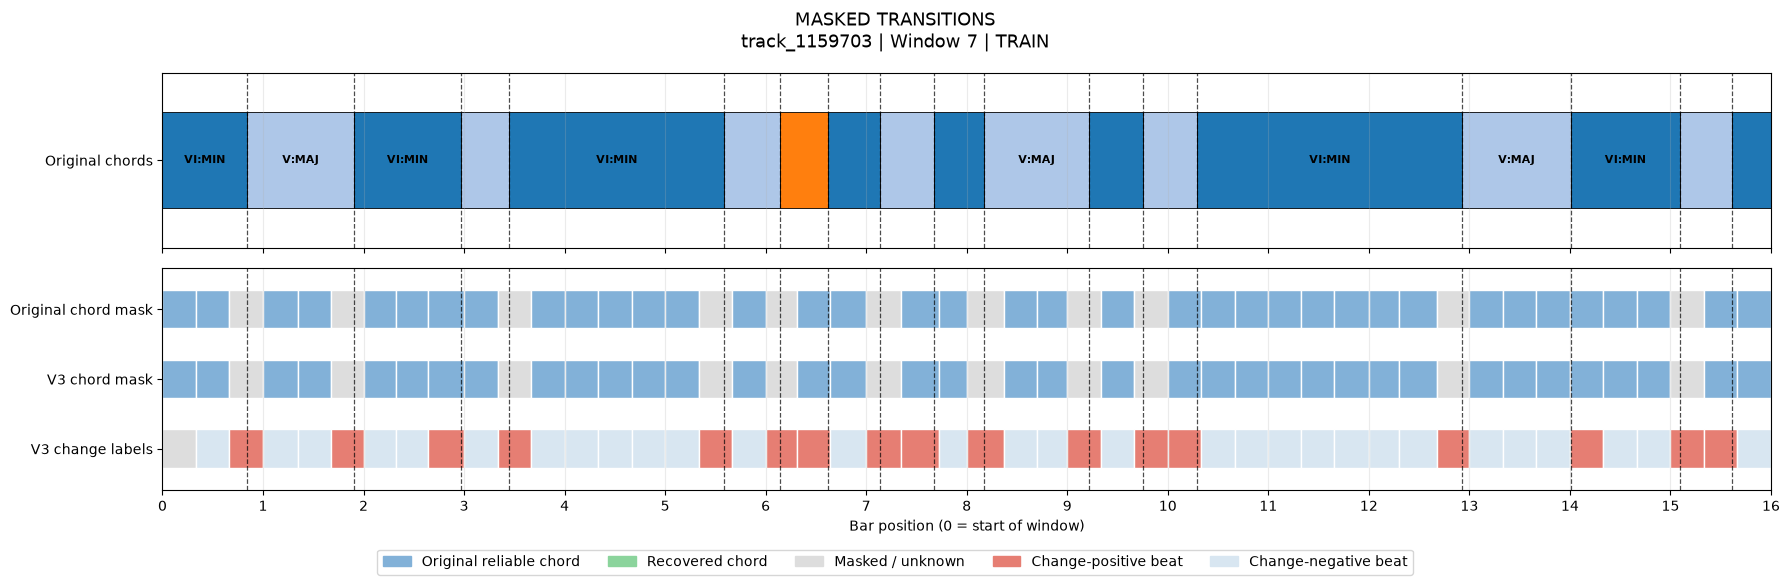

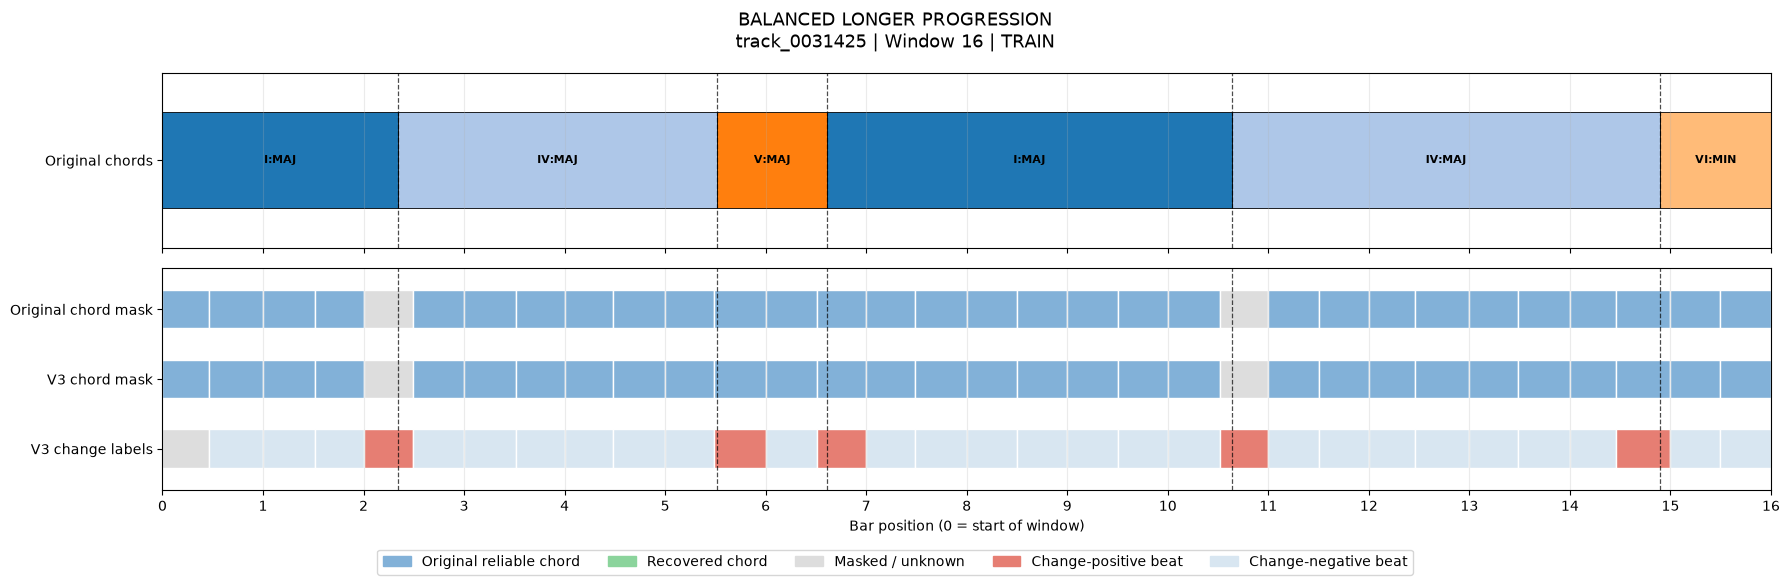

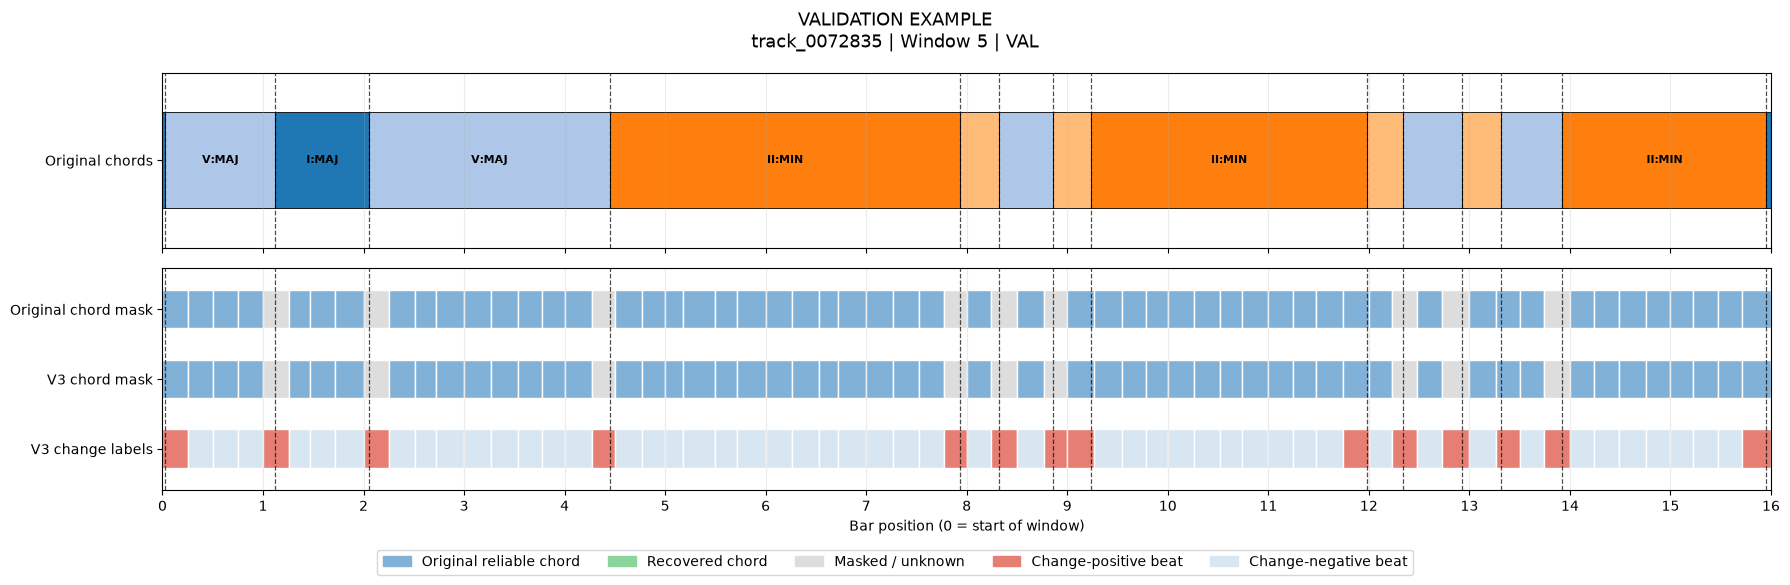


V3 VISUAL VALIDATION SUMMARY
--------------------------------


,Category,Track,Window,Original labels preserved,Recovered labels,Verified change positives,Original event boundaries
0,MASKED TRANSITIONS,track_1159703,7,37,0,17,17
1,BALANCED LONGER PROGRESSION,track_0031425,16,30,0,5,5
2,VALIDATION EXAMPLE,track_0072835,5,55,0,14,14



DETAILED CHANGE-POSITIVE BEATS
--------------------------------


,Beat,Bar,Beat in bar,Old chord,V3 chord,Source,Change,Occupancy
0,3,1,3,MASK,MASK,MASKED,1,0.518
1,6,2,3,MASK,MASK,MASKED,1,0.714
2,9,3,3,VI:MIN,VI:MIN,ORIGINAL,1,0.906
3,11,4,2,MASK,MASK,MASKED,1,0.661
4,17,6,2,MASK,MASK,MASKED,1,0.768
5,19,7,1,MASK,MASK,MASKED,1,0.536
6,20,7,2,III:MIN,III:MIN,ORIGINAL,1,0.933
7,22,8,1,MASK,MASK,MASKED,1,0.617
8,23,8,2,V:MAJ,V:MAJ,ORIGINAL,1,0.875
9,25,9,1,MASK,MASK,MASKED,1,0.531



FINAL VERIFICATION
--------------------------------
Saved V3 records examined: 3
Original chord labels preserved: YES
Positive change boundaries verified: YES
Dataset modified: NO
Model training performed: NO
Test labels examined: NO

Visual validation completed!


In [13]:
# ==========================================
# HARMONIC RHYTHM ANALYSIS
# CELL 11 — VISUAL VALIDATION OF V3 TARGETS
# ==========================================

import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.patches import Rectangle, Patch


# ==========================================
# 1. Configuration
# ==========================================

V3_PATH = (
    DATASET_PATH.parent
    / "windows_v3_filtered_event_aware.jsonl"
)

assert V3_PATH.exists()

rng = random.Random()

ROOT_NAMES = [
    "I", "♭II", "II", "♭III",
    "III", "IV", "♯IV", "V",
    "♭VI", "VI", "♭VII", "VII"
]


def chord_name(label):

    if label is None:
        return "MASK"

    root, family = label

    return f"{ROOT_NAMES[int(root)]}:{family}"


# ==========================================
# 2. Select representative examples
# ==========================================

# Example A:
# Training window with several change-positive
# positions lacking hard chord targets.

train_candidates = []

for key, targets in event_aware_train_targets.items():

    masked_changes = sum(
        t["change_valid"]
        and t["change_label"] == 1
        and not (
            t["old_valid"] or t["new_valid"]
        )
        for t in targets
    )

    if masked_changes >= 4:
        train_candidates.append(key)


assert train_candidates

example_a = rng.choice(train_candidates)


# Example B:
# A longer but balanced progression that passed
# our duration-based filtering.

balanced_pool = filter_preview_df[
    (filter_preview_df["reason"] == "KEEP")
    &
    (filter_preview_df["max_duration"] >= 3.5)
    &
    (filter_preview_df["duration_ratio"] < 2.0)
]

assert not balanced_pool.empty

balanced_row = balanced_pool.sample(n=1).iloc[0]

example_b = (
    balanced_row["track_id"],
    int(balanced_row["window_index"])
)


# Example C:
# Random validation window with several
# confirmed harmonic changes.

validation_candidates = [
    w for w in selected_windows
    if w["split"] == "val"
]

rng.shuffle(validation_candidates)

example_c = None

for window in validation_candidates[:100]:

    targets = build_event_aware_targets(window)

    positives = sum(
        t["change_valid"]
        and t["change_label"] == 1
        for t in targets
    )

    if positives >= 6:

        example_c = (
            window["track_id"],
            int(window["window_index"])
        )

        break

assert example_c is not None


selected_examples = {
    "MASKED TRANSITIONS": example_a,
    "BALANCED LONGER PROGRESSION": example_b,
    "VALIDATION EXAMPLE": example_c
}


# ==========================================
# 3. Retrieve selected records from saved V3
# ==========================================

required_keys = set(
    selected_examples.values()
)

saved_records = {}

with open(V3_PATH, "r", encoding="utf-8") as file:

    for line in file:

        # Skip test records without parsing them.

        if '"split": "test"' in line:
            continue

        record = json.loads(line)

        key = (
            record["track_id"],
            int(record["window_index"])
        )

        if key in required_keys:

            saved_records[key] = record

        if len(saved_records) == len(required_keys):
            break


assert set(saved_records) == required_keys


# ==========================================
# 4. Verify original labels and event boundaries
# ==========================================

def audit_saved_window(window):

    v3 = window["v3_targets"]

    n_beats = len(window["beat_targets"])

    assert all(
        len(values) == n_beats
        for values in v3.values()
    )

    # Reconstruct known chord-change boundaries
    # independently from stored V3 labels.

    regions = get_model_chord_regions(window)

    change_times = []

    for previous, current in zip(
        regions[:-1],
        regions[1:]
    ):

        if (
            previous["label"] is not None
            and current["label"] is not None
            and previous["label"] != current["label"]
            and abs(
                previous["end"] - current["start"]
            ) <= 0.02
        ):

            change_times.append(
                current["start"]
            )

    preserved = 0
    recovered = 0
    verified_positives = 0

    window_start = float(
        window["window_start_sec"]
    )

    for i, (old, grid) in enumerate(
        zip(
            window["beat_targets"],
            window["beat_grid"]
        )
    ):

        old_valid = (
            old.get("model_target_mask") == 1
            and old.get("root_id") is not None
            and old.get("family_id") is not None
        )

        source = v3["chord_label_source"][i]

        if old_valid:

            assert source == 1

            assert (
                v3["root_ids"][i]
                == int(old["root_id"])
            )

            assert (
                v3["family_ids"][i]
                == int(old["family_id"])
            )

            preserved += 1

        elif source == 2:

            assert window["split"] == "train"
            assert v3["chord_mask"][i] == 1

            recovered += 1

        if (
            v3["change_mask"][i] == 1
            and v3["change_labels"][i] == 1
        ):

            start = (
                window_start
                + float(grid["time_sec"])
            )

            end = (
                start
                + float(grid["duration_sec"])
            )

            matches_event = any(
                start - 1e-6 <= t < end - 1e-6
                for t in change_times
            )

            assert matches_event, (
                f"Unmatched positive at beat {i}"
            )

            verified_positives += 1

    return {
        "Original labels preserved": preserved,
        "Recovered labels": recovered,
        "Verified change positives": verified_positives,
        "Original event boundaries": len(change_times)
    }


# ==========================================
# 5. Plot original events and V3 supervision
# ==========================================

def plot_v3_audit(window, category):

    v3 = window["v3_targets"]

    regions = get_model_chord_regions(window)

    bar_intervals = get_bar_intervals(window)

    window_start = float(
        window["window_start_sec"]
    )

    fig, (ax1, ax2) = plt.subplots(
        2, 1,
        figsize=(18, 5.5),
        sharex=True,
        gridspec_kw={
            "height_ratios": [1.1, 1.4]
        }
    )

    # --------------------------------------
    # A. Original chord timeline
    # --------------------------------------

    labels = list(dict.fromkeys(
        r["label"] for r in regions
    ))

    cmap = plt.get_cmap("tab20")

    colors = {
        label: cmap(i % 20)
        for i, label in enumerate(labels)
    }

    for region in regions:

        x0 = time_to_bar_position(
            region["start"],
            bar_intervals
        )

        x1 = time_to_bar_position(
            region["end"],
            bar_intervals
        )

        width = max(0, x1 - x0)

        ax1.barh(
            0,
            width,
            left=x0,
            height=0.55,
            color=colors[region["label"]],
            edgecolor="black",
            linewidth=0.6
        )

        if width >= 0.65:

            ax1.text(
                x0 + width / 2,
                0,
                chord_name(region["label"]),
                ha="center",
                va="center",
                fontsize=8,
                fontweight="bold"
            )

    ax1.set_yticks([0])
    ax1.set_yticklabels(["Original chords"])

    ax1.set_ylim(-0.5, 0.5)

    # --------------------------------------
    # B. Original chord-change boundaries
    # --------------------------------------

    actual_changes = []

    for previous, current in zip(
        regions[:-1],
        regions[1:]
    ):

        if (
            previous["label"] is not None
            and current["label"] is not None
            and previous["label"] != current["label"]
            and abs(
                previous["end"] - current["start"]
            ) <= 0.02
        ):

            x = time_to_bar_position(
                current["start"],
                bar_intervals
            )

            actual_changes.append(x)

    # --------------------------------------
    # C. Draw original and V3 beat targets
    # --------------------------------------

    ROWS = {
        "Original chord mask": 2,
        "V3 chord mask": 1,
        "V3 change labels": 0
    }

    for i, (beat, grid) in enumerate(
        zip(
            window["beat_targets"],
            window["beat_grid"]
        )
    ):

        start_sec = (
            window_start
            + float(grid["time_sec"])
        )

        end_sec = (
            start_sec
            + float(grid["duration_sec"])
        )

        x0 = time_to_bar_position(
            start_sec,
            bar_intervals
        )

        x1 = time_to_bar_position(
            end_sec,
            bar_intervals
        )

        width = max(0, x1 - x0)

        old_valid = (
            beat.get("model_target_mask") == 1
        )

        source = v3["chord_label_source"][i]

        change_mask = v3["change_mask"][i]

        change_label = v3["change_labels"][i]

        # Original chord supervision.

        old_color = (
            "#82B1D8"
            if old_valid
            else "#DDDDDD"
        )

        ax2.barh(
            ROWS["Original chord mask"],
            width,
            left=x0,
            height=0.55,
            color=old_color,
            edgecolor="white"
        )

        # New chord supervision.

        if source == 1:
            new_color = "#82B1D8"

        elif source == 2:
            new_color = "#8BD49C"

        else:
            new_color = "#DDDDDD"

        ax2.barh(
            ROWS["V3 chord mask"],
            width,
            left=x0,
            height=0.55,
            color=new_color,
            edgecolor="white"
        )

        # Harmonic-change supervision.

        if not change_mask:
            change_color = "#DDDDDD"

        elif change_label == 1:
            change_color = "#E67E73"

        else:
            change_color = "#D8E6F1"

        ax2.barh(
            ROWS["V3 change labels"],
            width,
            left=x0,
            height=0.55,
            color=change_color,
            edgecolor="white"
        )

    # Exact original boundaries as dashed lines.

    for x in actual_changes:

        ax1.axvline(
            x,
            color="black",
            linestyle="--",
            linewidth=0.9,
            alpha=0.7
        )

        ax2.axvline(
            x,
            color="black",
            linestyle="--",
            linewidth=0.9,
            alpha=0.7
        )

    # --------------------------------------
    # D. Formatting
    # --------------------------------------

    ax2.set_yticks(
        list(ROWS.values())
    )

    ax2.set_yticklabels(
        list(ROWS.keys())
    )

    ax2.set_ylim(-0.6, 2.6)

    for ax in (ax1, ax2):

        ax.set_xlim(0, 16)

        ax.set_xticks(
            np.arange(0, 17)
        )

        ax.grid(
            axis="x",
            alpha=0.25
        )

    ax2.set_xlabel(
        "Bar position (0 = start of window)"
    )

    fig.suptitle(
        f"{category}\n"
        f"{window['track_id']} | "
        f"Window {window['window_index']} | "
        f"{window['split'].upper()}",
        fontsize=13
    )

    legend = [
        Patch(
            color="#82B1D8",
            label="Original reliable chord"
        ),
        Patch(
            color="#8BD49C",
            label="Recovered chord"
        ),
        Patch(
            color="#DDDDDD",
            label="Masked / unknown"
        ),
        Patch(
            color="#E67E73",
            label="Change-positive beat"
        ),
        Patch(
            color="#D8E6F1",
            label="Change-negative beat"
        )
    ]

    fig.legend(
        handles=legend,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.06),
        ncol=5
    )

    plt.tight_layout()
    plt.show()


# ==========================================
# 6. Run audits and display charts
# ==========================================

audit_results = []

for category, key in selected_examples.items():

    window = saved_records[key]

    audit = audit_saved_window(
        window
    )

    audit_results.append({
        "Category": category,
        "Track": key[0],
        "Window": key[1],
        **audit
    })

    plot_v3_audit(
        window,
        category
    )


print("\nV3 VISUAL VALIDATION SUMMARY")
print("--------------------------------")

display(
    pd.DataFrame(audit_results)
)


# ==========================================
# 7. Show detailed change-label examples
# ==========================================

# Use the first selected example.

window = saved_records[example_a]

v3 = window["v3_targets"]

rows = []

for i, (beat, grid) in enumerate(
    zip(
        window["beat_targets"],
        window["beat_grid"]
    )
):

    if (
        v3["change_mask"][i] != 1
        or v3["change_labels"][i] != 1
    ):
        continue

    old_label = (
        (
            int(beat["root_id"]),
            normalize_family(beat["family"])
        )
        if beat.get("model_target_mask") == 1
        else None
    )

    source = v3["chord_label_source"][i]

    new_label = (
        (
            v3["root_ids"][i],
            next(
                family
                for family, family_id
                in family_to_id.items()
                if family_id == v3["family_ids"][i]
            )
        )
        if v3["chord_mask"][i] == 1
        else None
    )

    rows.append({
        "Beat": i + 1,
        "Bar": int(grid["bar_index"]) + 1,
        "Beat in bar": grid["beat_in_bar"],
        "Old chord": chord_name(old_label),
        "V3 chord": chord_name(new_label),
        "Source": (
            "RECOVERED" if source == 2
            else "ORIGINAL" if source == 1
            else "MASKED"
        ),
        "Change": 1,
        "Occupancy": v3["chord_occupancy"][i]
    })


print("\nDETAILED CHANGE-POSITIVE BEATS")
print("--------------------------------")

display(
    pd.DataFrame(rows).head(25).round(3)
)


# ==========================================
# 8. Final verification
# ==========================================

print("\nFINAL VERIFICATION")
print("--------------------------------")

print("Saved V3 records examined:", len(saved_records))
print("Original chord labels preserved: YES")
print("Positive change boundaries verified: YES")

print("Dataset modified: NO")
print("Model training performed: NO")
print("Test labels examined: NO")

print("\nVisual validation completed!")